<div style="text-align: center;">
    <h1><b><span style="color: yellow;">Investigating the Impact of the COVID-19 Pandemic on the Populations and Unemployment Rates of the United States and New Zealand</span></b></h1>
</div>


### <span style="color:yellow">ABSTRACT</span>

The aim of this project is to investigate the impact of the COVID-19 pandemic on the populations and unemployment rates of the United States and New Zealand. It also aims to investigate whether certain populations were disproportionately affected by the pandemic. It follows the full data science pipeline, from data extraction to visualization, ensuring that insights can be understood by both technical and non-technical audiences. Below is an outline of the project with the steps taken to complete the pipeline:

1) Introduction: Providing background information on the project and stating the project goals.

2) IDB Data Introduction: Introducing one of the datasets used in this project - "idb". 

3) IDB Data Transformation: Transforming and cleaning the original idb dataset to fit the goals of this project.

4) Unemployment Data Introduction: Introducing the second dataset used in this project - the unemployment dataset. 

5) Unemployment Data Transformation: Transforming and cleaning the original unemployment dataset to fit the goals of this project.

6) Data Merging: Merging the transformed IDB data with the transformed Unemployment data to create one cohesive dataset.

7) Data Exploration: Performing exploratory data analysis (EDA) on the merged dataset.

8) Data Analysis: Doing an in-depth analysis of the merged data, addressing the project goals listed in the introduction.

8) Data Loading: Loading the merged data into SQL and creating a data schema.

9) Data Visualizations: Creating interactive data visualizations of the most significant graphs/findings using Dash.

10) Conclusion and Future Directions: Wrapping up the project, highlighting the major results and providing suggestions for future work.

### <span style="color:yellow">INTRODUCTION</span>


The COVID-19 pandemic had profound effects on populations and economies worldwide, disrupting demographic trends and labor markets. While every country faced challenges, the responses to the pandemic varied significantly. The United States and New Zealand, in particular, took vastly different approaches in managing the crisis. According to law professor Richard Parker, "New Zealand’s response was centrally planned and tightly managed while the U.S. response was incoherent and decentralized" (Parker, n.d.). The US began administering COVID-19 vaccines in December 2020 (US Health and Human Services, 2024), whereas New Zealand started in February 2021 (National Institute of Health, 2023). These contrasting strategies make the two countries compelling cases for comparison.

This project investigates the impact of the pandemic on population dynamics and unemployment rates in the United States and New Zealand. Specifically, it examines the following trends:

- Population size before, during, and after COVID-19
- Gender distributions before, during, and after COVID-19
- Age distributions before, during, and after COVID-19
- Unemployment rates before, during, and after COVID-19, and potential correlations with demographic variables

To analyze these trends, I use two primary datasets. The first is from the International Database (IDB) from the U.S. Census Bureau, which provides population estimates, demographic breakdowns, and future projections for over 200 countries and regions worldwide (United States Census Bureau, 2024). Specifically, I utilize the "idbsingleyear.txt" dataset, which contains population data segmented by year, age group, and sex, from 1950 to 2024, with projections extending to 2100.

Since the IDB dataset does not include unemployment data, I supplement my analysis with the "global_unemployment_data.csv" dataset, sourced from Kaggle. This dataset, compiled from the International Labor Organization (ILO), provides unemployment rates by age and sex for various countries from 2014 to 2024 (Kaggle, 2024).

By integrating these datasets, this project aims to provide a data-driven analysis of how the pandemic influenced demographic and unemployment trends in two countries with starkly different pandemic responses.

Link to the IDB dataset: https://www.census.gov/programs-surveys/international-programs/about/idb.html

Link to the Unemployment dataset: https://www.kaggle.com/datasets/sazidthe1/global-unemployment-data

### <span style="color:yellow">IDB DATA - INTRODUCTION</span>

As mentioned, the primary dataset I work with in this project is the 'idbsingleyear.txt" dataset. It contains 5 columns - "#YR" (Year), "GEO_ID" (Region), "AGE", "SEX", and "POP" (Population size). The year represents a particular year, the geo_id represents a region, the age represents a specific age, the sex represents the total amount of people of that sex where 0 = both, 1 = male, and 2 = female, and the population represents the population size. 

The following is a row from the dataset:

#YR  GEO_ID    AGE SEX POP      
1990|W140000WOAD|0|0|504 

This row indicates that in 1990, in Andorra (represented by the last two letters "AD" in the "GEO_ID" code), there were 504 people (both males and females, indicated by the "0" in "SEX") of infant age (< 1 year old).  

The following is what the first couple of rows of the dataset looks like and how many total rows it has:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display  

file_path = r"C:\Users\Yogin\Documents\Dev10-Midterm\idbzip\idbsingleyear.txt"
original_idb_df = pd.read_csv(file_path, delimiter='|')

display(original_idb_df.head()) 
print("NUMBER OF ROWS:")
print(len(original_idb_df))


,#YR,GEO_ID,AGE,SEX,POP
0,1990,W140000WOAD,0,0,504
1,1990,W140000WOAD,0,1,264
2,1990,W140000WOAD,0,2,240
3,1990,W140000WOAD,1,0,550
4,1990,W140000WOAD,1,1,279


NUMBER OF ROWS:
7923753


### <span style="color:yellow">IDB DATA - TRANSFORMATION</span>

Clearly, the idbsingleyear.txt dataset is large, with over 7 million data points. However, for the purpose of this project, only certain data points are needed such as data points related to only the US and New Zealand and data points surrounding the years around the COVID pandemic; I have chosen focus on the years 2018-2019 for "pre-Covid", 2020-2023 for "during Covid", and 2024 for "post-Covid". Hence, I will be cleaning and transforming the original "idbsingleyear.txt" dataset (dataframe name "original_idb_df" ) into a new dataset - "idb_transformed.csv" (dataframe name "transforming_idb_df") to create a dataset that is easier to read and use and more relevant towards the purposes of this project. Below are the steps used to transform the data:


Step 1 - Translating "GEO_ID" to the corresponding country:

In [2]:
country_map = {
    'AF': 'Afghanistan', 'AL': 'Albania', 'DZ': 'Algeria', 'AS': 'American Samoa', 
    'AD': 'Andorra', 'AO': 'Angola', 'AI': 'Anguilla', 'AG': 'Antigua and Barbuda', 
    'AR': 'Argentina', 'AM': 'Armenia', 'AW': 'Aruba', 'AU': 'Australia', 
    'AT': 'Austria', 'AZ': 'Azerbaijan', 'BS': 'Bahamas, The', 'BH': 'Bahrain', 
    'BD': 'Bangladesh', 'BB': 'Barbados', 'BY': 'Belarus', 'BE': 'Belgium', 
    'BZ': 'Belize', 'BJ': 'Benin', 'BM': 'Bermuda', 'BT': 'Bhutan', 
    'BO': 'Bolivia', 'BA': 'Bosnia and Herzegovina', 'BW': 'Botswana', 'BR': 'Brazil', 
    'BN': 'Brunei', 'BG': 'Bulgaria', 'BF': 'Burkina Faso', 'MM': 'Burma', 
    'BI': 'Burundi', 'CV': 'Cabo Verde', 'KH': 'Cambodia', 'CM': 'Cameroon', 
    'CA': 'Canada', 'KY': 'Cayman Islands', 'CF': 'Central African Republic', 'TD': 'Chad', 
    'CL': 'Chile', 'CN': 'China', 'CO': 'Colombia', 'KM': 'Comoros', 
    'CG': 'Congo (Brazzaville)', 'CD': 'Congo (Kinshasa)', 'CK': 'Cook Islands', 
    'CR': 'Costa Rica', 'CI': "Côte d'Ivoire", 'HR': 'Croatia', 'CU': 'Cuba', 
    'CW': 'Curaçao', 'CY': 'Cyprus', 'CZ': 'Czechia', 'DK': 'Denmark', 
    'DJ': 'Djibouti', 'DM': 'Dominica', 'DO': 'Dominican Republic', 'EC': 'Ecuador', 
    'EG': 'Egypt', 'SV': 'El Salvador', 'GQ': 'Equatorial Guinea', 'ER': 'Eritrea', 
    'EE': 'Estonia', 'SZ': 'Eswatini', 'ET': 'Ethiopia', 'FO': 'Faroe Islands', 
    'FJ': 'Fiji', 'FI': 'Finland', 'FR': 'France', 'PF': 'French Polynesia', 
    'GA': 'Gabon', 'GM': 'Gambia, The', 'XG': 'Gaza Strip', 'GE': 'Georgia', 
    'DE': 'Germany', 'GH': 'Ghana', 'GI': 'Gibraltar', 'GR': 'Greece', 
    'GL': 'Greenland', 'GD': 'Grenada', 'GU': 'Guam', 'GT': 'Guatemala', 
    'GG': 'Guernsey', 'GN': 'Guinea', 'GW': 'Guinea-Bissau', 'GY': 'Guyana', 
    'HT': 'Haiti', 'HN': 'Honduras', 'HK': 'Hong Kong', 'HU': 'Hungary', 
    'IS': 'Iceland', 'IN': 'India', 'ID': 'Indonesia', 'IR': 'Iran', 
    'IQ': 'Iraq', 'IE': 'Ireland', 'IM': 'Isle of Man', 'IL': 'Israel', 
    'IT': 'Italy', 'JM': 'Jamaica', 'JP': 'Japan', 'JE': 'Jersey', 
    'JO': 'Jordan', 'KZ': 'Kazakhstan', 'KE': 'Kenya', 'KI': 'Kiribati', 
    'KP': 'Korea, North', 'KR': 'Korea, South', 'XK': 'Kosovo', 'KW': 'Kuwait', 
    'KG': 'Kyrgyzstan', 'LA': 'Laos', 'LV': 'Latvia', 'LB': 'Lebanon', 
    'LS': 'Lesotho', 'LR': 'Liberia', 'LY': 'Libya', 'LI': 'Liechtenstein', 
    'LT': 'Lithuania', 'LU': 'Luxembourg', 'MO': 'Macau', 'MG': 'Madagascar', 
    'MW': 'Malawi', 'MY': 'Malaysia', 'MV': 'Maldives', 'ML': 'Mali', 
    'MT': 'Malta', 'MH': 'Marshall Islands', 'MR': 'Mauritania', 'MU': 'Mauritius', 
    'MX': 'Mexico', 'FM': 'Micronesia, Federated States of', 'MD': 'Moldova', 
    'MC': 'Monaco', 'MN': 'Mongolia', 'ME': 'Montenegro', 'MS': 'Montserrat', 
    'MA': 'Morocco', 'MZ': 'Mozambique', 'NA': 'Namibia', 'NR': 'Nauru', 
    'NP': 'Nepal', 'NL': 'Netherlands', 'NC': 'New Caledonia', 'NZ': 'New Zealand', 
    'NI': 'Nicaragua', 'NE': 'Niger', 'NG': 'Nigeria', 'MK': 'North Macedonia', 
    'MP': 'Northern Mariana Islands', 'NO': 'Norway', 'OM': 'Oman', 'PK': 'Pakistan', 
    'PW': 'Palau', 'PA': 'Panama', 'PG': 'Papua New Guinea', 'PY': 'Paraguay', 
    'PE': 'Peru', 'PH': 'Philippines', 'PL': 'Poland', 'PT': 'Portugal', 
    'PR': 'Puerto Rico', 'QA': 'Qatar', 'RO': 'Romania', 'RU': 'Russia', 
    'RW': 'Rwanda', 'BL': 'Saint Barthelemy', 'SH': 'Saint Helena, Ascension, and Tristan da Cunha', 
    'KN': 'Saint Kitts and Nevis', 'LC': 'Saint Lucia', 'MF': 'Saint Martin', 
    'PM': 'Saint Pierre and Miquelon', 'VC': 'Saint Vincent and the Grenadines', 'WS': 'Samoa', 
    'SM': 'San Marino', 'ST': 'Sao Tome and Principe', 'SA': 'Saudi Arabia', 'SN': 'Senegal', 
    'RS': 'Serbia', 'SC': 'Seychelles', 'SL': 'Sierra Leone', 'SG': 'Singapore', 
    'SX': 'Sint Maarten', 'SK': 'Slovakia', 'SI': 'Slovenia', 'SB': 'Solomon Islands', 
    'SO': 'Somalia', 'ZA': 'South Africa', 'SS': 'South Sudan', 'ES': 'Spain', 
    'LK': 'Sri Lanka', 'SD': 'Sudan', 'SR': 'Suriname', 'SE': 'Sweden', 
    'CH': 'Switzerland', 'SY': 'Syria', 'TW': 'Taiwan', 'TJ': 'Tajikistan', 
    'TZ': 'Tanzania', 'TH': 'Thailand', 'TL': 'Timor-Leste', 'TG': 'Togo', 
    'TO': 'Tonga', 'TT': 'Trinidad and Tobago', 'TN': 'Tunisia', 'TR': 'Turkey', 
    'TM': 'Turkmenistan', 'TC': 'Turks and Caicos Islands', 'TV': 'Tuvalu', 'UG': 'Uganda', 
    'UA': 'Ukraine', 'AE': 'United Arab Emirates', 'GB': 'United Kingdom', 'US': 'United States', 
    'UY': 'Uruguay', 'UZ': 'Uzbekistan', 'VU': 'Vanuatu', 'VE': 'Venezuela', 'VN': 'Vietnam', 
    'VG': 'Virgin Islands, British', 'VI': 'Virgin Islands, U.S.', 'WF': 'Wallis and Futuna', 
    'XW': 'West Bank', 'YE': 'Yemen', 'ZM': 'Zambia', 'ZW': 'Zimbabwe'
}



transforming_idb_df = original_idb_df.copy()

def geo_to_country(geo_id):
    country_code = str(geo_id)[-2:]
    return country_map.get(country_code, "Unknown")

transforming_idb_df['GEO_ID'] = transforming_idb_df['GEO_ID'].apply(geo_to_country)

display(transforming_idb_df.head())



,#YR,GEO_ID,AGE,SEX,POP
0,1990,Andorra,0,0,504
1,1990,Andorra,0,1,264
2,1990,Andorra,0,2,240
3,1990,Andorra,1,0,550
4,1990,Andorra,1,1,279


Step 2 - Changing the column names so they're easier to read/understand:

In [3]:
transforming_idb_df.rename(columns={"#YR": "Year", "GEO_ID": "Country", "AGE": "Age", "SEX": "Sex", "POP": "Population Size"}, inplace=True)
display(transforming_idb_df.head())

,Year,Country,Age,Sex,Population Size
0,1990,Andorra,0,0,504
1,1990,Andorra,0,1,264
2,1990,Andorra,0,2,240
3,1990,Andorra,1,0,550
4,1990,Andorra,1,1,279


Step 3 - Keep only the rows with "United States" and "New Zealand":

In [4]:
transforming_idb_df = transforming_idb_df[transforming_idb_df['Country'].isin(['United States', 'New Zealand'])]
display(transforming_idb_df.head())

print("Unique Countries:", transforming_idb_df['Country'].unique())

old_us_count = original_idb_df[original_idb_df['GEO_ID'].str.endswith('US')].shape[0]
old_nz_count = original_idb_df[original_idb_df['GEO_ID'].str.endswith('NZ')].shape[0]

print("Original DF - Instances with GEO_ID ending in 'US':", old_us_count)
print("Original DF - Instances with GEO_ID ending in 'NZ':", old_nz_count)

new_us_count = transforming_idb_df[transforming_idb_df['Country'] == 'United States'].shape[0]
new_nz_count = transforming_idb_df[transforming_idb_df['Country'] == 'New Zealand'].shape[0]

print("New DF - Instances for 'United States':", new_us_count)
print("New DF - Instances for 'New Zealand':", new_nz_count)

,Year,Country,Age,Sex,Population Size
5415519,1986,New Zealand,0,0,52299
5415520,1986,New Zealand,0,1,26728
5415521,1986,New Zealand,0,2,25571
5415522,1986,New Zealand,1,0,50456
5415523,1986,New Zealand,1,1,25813


Unique Countries: ['New Zealand' 'United States']
Original DF - Instances with GEO_ID ending in 'US': 27573
Original DF - Instances with GEO_ID ending in 'NZ': 34845
New DF - Instances for 'United States': 27573
New DF - Instances for 'New Zealand': 34845


From the output above, it seems like all countries except NZ and US were filtered out correctly.

Step 4 - Keep only years from 2018 - 2024:

In [5]:
transforming_idb_df = transforming_idb_df[(transforming_idb_df['Year'] >= 2018) & (transforming_idb_df['Year'] <= 2024)]

display(transforming_idb_df.head())

print("Unique Years in transformed DataFrame:", transforming_idb_df['Year'].unique())

old_filtered_df = original_idb_df[
    (original_idb_df['GEO_ID'].str.endswith(('US', 'NZ'))) & 
    (original_idb_df['#YR'].between(2018, 2024))
]


old_us_count = old_filtered_df[old_filtered_df['GEO_ID'].str.endswith('US')].shape[0]
old_nz_count = old_filtered_df[old_filtered_df['GEO_ID'].str.endswith('NZ')].shape[0]

print("Original DF - Instances for 'United States' (2018-2024):", old_us_count)
print("Original DF - Instances for 'New Zealand' (2018-2024):", old_nz_count)

new_us_count = transforming_idb_df[transforming_idb_df['Country'] == 'United States'].shape[0]
new_nz_count = transforming_idb_df[transforming_idb_df['Country'] == 'New Zealand'].shape[0]

print("New DF - Instances for 'United States' (2018-2024):", new_us_count)
print("New DF - Instances for 'New Zealand' (2018-2024):", new_nz_count)

,Year,Country,Age,Sex,Population Size
5425215,2018,New Zealand,0,0,60452
5425216,2018,New Zealand,0,1,31028
5425217,2018,New Zealand,0,2,29424
5425218,2018,New Zealand,1,0,60458
5425219,2018,New Zealand,1,1,31049


Unique Years in transformed DataFrame: [2018 2019 2020 2021 2022 2023 2024]
Original DF - Instances for 'United States' (2018-2024): 2121
Original DF - Instances for 'New Zealand' (2018-2024): 2121
New DF - Instances for 'United States' (2018-2024): 2121
New DF - Instances for 'New Zealand' (2018-2024): 2121


From the output above, it seems like all the years were filtered out correctly.

Step 5 - Add a column "Era" that categorizes each year as either "Pre COVID", "During COVID", and "Post COVID" where 2018-2019 is "Pre COVID", 2020-2023 is "During COVID", and 2024 is "Post COVID":

(This may make it easier for certain analysis/visualization steps in the future).

In [6]:
def categorize_era(year):
    if 2018 <= year <= 2019:
        return "Pre COVID"
    elif 2020 <= year <= 2023:
        return "During COVID"
    elif year == 2024:
        return "Post COVID"
    else:
        return "Unknown"  
    
transforming_idb_df["Era"] = transforming_idb_df["Year"].apply(categorize_era)

display(transforming_idb_df.head())

,Year,Country,Age,Sex,Population Size,Era
5425215,2018,New Zealand,0,0,60452,Pre COVID
5425216,2018,New Zealand,0,1,31028,Pre COVID
5425217,2018,New Zealand,0,2,29424,Pre COVID
5425218,2018,New Zealand,1,0,60458,Pre COVID
5425219,2018,New Zealand,1,1,31049,Pre COVID


Step 6 - Check to see if there are any "odd"/null values in any of the columns:

In [7]:
for col in transforming_idb_df.columns:
    print(f"Unique values in {col}:\n", transforming_idb_df[col].unique(), "\n")

print(transforming_idb_df.isnull().sum())

# Checking if all values in "Population Size" are integers (since its output in truncated)
if transforming_idb_df['Population Size'].apply(lambda x: isinstance(x, int)).all():
    print("All values in 'Population Size' are whole numbers.")
else:
    print("There are non-integer values in 'Population Size'.")


Unique values in Year:
 [2018 2019 2020 2021 2022 2023 2024] 

Unique values in Country:
 ['New Zealand' 'United States'] 

Unique values in Age:
 [  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17
  18  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35
  36  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53
  54  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71
  72  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89
  90  91  92  93  94  95  96  97  98  99 100] 

Unique values in Sex:
 [0 1 2] 

Unique values in Population Size:
 [ 60452  31028  29424 ... 101480  21933  79547] 

Unique values in Era:
 ['Pre COVID' 'During COVID' 'Post COVID'] 

Year               0
Country            0
Age                0
Sex                0
Population Size    0
Era                0
dtype: int64
All values in 'Population Size' are whole numbers.


From the output above, it seems like there are no "odd" values in the new transformed dataframe - "transforming_idb_df".

Step 7 - Saving "transforming_idb_df" to a .csv file, "idb_transformed.csv":

In [8]:
transforming_idb_df.to_csv("idb_transformed.csv", index=False)
display(transforming_idb_df)

,Year,Country,Age,Sex,Population Size,Era
5425215,2018,New Zealand,0,0,60452,Pre COVID
5425216,2018,New Zealand,0,1,31028,Pre COVID
5425217,2018,New Zealand,0,2,29424,Pre COVID
5425218,2018,New Zealand,1,0,60458,Pre COVID
5425219,2018,New Zealand,1,1,31049,Pre COVID
...,...,...,...,...,...,...
7327747,2024,United States,99,1,15440,Post COVID
7327748,2024,United States,99,2,47466,Post COVID
7327749,2024,United States,100,0,101480,Post COVID
7327750,2024,United States,100,1,21933,Post COVID


### <span style="color:yellow">UNEMPLOYMENT DATA - INTRODUCTION</span>

As mentioned, the global unemployment data (saved in "global_unemployment_data.csv") was obtained from Kaggle where the data was recieved from the ILO. The dataset has information on unemployment rates by age and sex for various countries spanning from 2014 - 2024. It contains following 16 columns:

1) country_name: Name of the Country
2) indicator_name: Type of Unemployment Indicator (the values for this column are "Unemployment rate by sex and age" for the entire dataset)
3) sex: Male/Female
4) age_group: Categorized Age Groups (under 15, 15-24, 25+)
5) age_categories:	Specific Age Categories (Children, Youth, Adults) (where under 15 is children, 15-24 is youth, and 25+ is adults)
6) 2014: Annual Unemployment Rate for the year 2014 (in %)
7) 2015: Annual Unemployment Rate for the year 2015 (in %)
8) 2016: Annual Unemployment Rate for the year 2016 (in %)
9) 2017: Annual Unemployment Rate for the year 2017 (in %)
10) 2018: Annual Unemployment Rate for the year 2018 (in %)
11) 2019: Annual Unemployment Rate for the year 2019 (in %)
12) 2020: Annual Unemployment Rate for the year 2020 (in %)
13) 2021: Annual Unemployment Rate for the year 2021 (in %)
14) 2022: Annual Unemployment Rate for the year 2022 (in %)
15) 2023: Annual Unemployment Rate for the year 2023 (in %)
16) 2024: Annual Unemployment Rate for the year 2024 (in %)


This is what the first couple rows of the dataset look like:

In [9]:
file_path = r"C:\Users\Yogin\Downloads\global_unemployment_data.csv"
original_unemployment_df = pd.read_csv(file_path)

original_unemployment_df.head()

,country_name,indicator_name,sex,age_group,age_categories,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Afghanistan,Unemployment rate by sex and age,Female,15-24,Youth,13.340,15.974,18.570,21.137,20.649,20.154,21.228,21.640,30.561,32.200,33.332
1,Afghanistan,Unemployment rate by sex and age,Female,25+,Adults,8.576,9.014,9.463,9.920,11.223,12.587,14.079,14.415,23.818,26.192,28.298
2,Afghanistan,Unemployment rate by sex and age,Female,Under 15,Children,10.306,11.552,12.789,14.017,14.706,15.418,16.783,17.134,26.746,29.193,30.956
3,Afghanistan,Unemployment rate by sex and age,Male,15-24,Youth,9.206,11.502,13.772,16.027,15.199,14.361,14.452,15.099,16.655,18.512,19.770
4,Afghanistan,Unemployment rate by sex and age,Male,25+,Adults,6.463,6.879,7.301,7.728,7.833,7.961,8.732,9.199,11.357,12.327,13.087


### <span style="color:yellow">UNEMPLOYMENT DATA - TRANSFORMATION</span>

Here, we are going to transform the global unemployment dataset to meets the need of this specific project. We will save the transformed data in a df called "unemployment_transformed_df" and then to a csv file called "unemployment_transformed.csv". Below are the steps taken:

Step 1 - Remove any countries/regions that aren't the United States or New Zealand:

In [10]:
countries_to_keep = ["United States", "New Zealand"]
unemployment_transformed_df = original_unemployment_df[original_unemployment_df["country_name"].isin(countries_to_keep)]
display(unemployment_transformed_df.head())

unique_countries = unemployment_transformed_df["country_name"].unique()
print("Unique countries in transformed dataset:", unique_countries)

,country_name,indicator_name,sex,age_group,age_categories,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
720,New Zealand,Unemployment rate by sex and age,Female,15-24,Youth,14.755,13.853,13.645,13.372,11.015,11.493,12.627,10.126,9.057,10.487,11.530
721,New Zealand,Unemployment rate by sex and age,Female,25+,Adults,4.564,4.444,4.059,3.793,3.337,3.172,3.682,2.804,2.543,2.755,2.961
722,New Zealand,Unemployment rate by sex and age,Female,Under 15,Children,6.126,5.908,5.523,5.240,4.503,4.419,4.986,3.890,3.536,3.929,4.237
723,New Zealand,Unemployment rate by sex and age,Male,15-24,Youth,13.561,13.972,13.420,12.691,12.650,11.160,12.283,10.763,9.586,10.832,11.925
724,New Zealand,Unemployment rate by sex and age,Male,25+,Adults,3.171,3.287,3.221,2.788,2.735,2.598,2.930,2.499,1.975,2.299,2.566


Unique countries in transformed dataset: ['New Zealand' 'United States']


From the output above, it seems like the countries were filtered out correctly.

Step 2 - Dropping the unneeded year columns:

In [11]:
columns_to_keep = ['country_name', 'indicator_name', 'sex', 'age_group', 'age_categories', '2018', '2019', '2020', '2021', '2022', '2023', '2024']
unemployment_transformed_df = unemployment_transformed_df[columns_to_keep]
display(unemployment_transformed_df)

print("Columns after dropping unnecessary years:")
print(unemployment_transformed_df.columns)

,country_name,indicator_name,sex,age_group,age_categories,2018,2019,2020,2021,2022,2023,2024
720,New Zealand,Unemployment rate by sex and age,Female,15-24,Youth,11.015,11.493,12.627,10.126,9.057,10.487,11.530
721,New Zealand,Unemployment rate by sex and age,Female,25+,Adults,3.337,3.172,3.682,2.804,2.543,2.755,2.961
722,New Zealand,Unemployment rate by sex and age,Female,Under 15,Children,4.503,4.419,4.986,3.890,3.536,3.929,4.237
723,New Zealand,Unemployment rate by sex and age,Male,15-24,Youth,12.650,11.160,12.283,10.763,9.586,10.832,11.925
724,New Zealand,Unemployment rate by sex and age,Male,25+,Adults,2.735,2.598,2.930,2.499,1.975,2.299,2.566
725,New Zealand,Unemployment rate by sex and age,Male,Under 15,Children,4.193,3.829,4.255,3.680,3.085,3.550,3.910
1074,United States,Unemployment rate by sex and age,Female,15-24,Youth,7.657,7.313,14.794,8.865,7.437,7.033,7.671
1075,United States,Unemployment rate by sex and age,Female,25+,Adults,3.234,3.024,7.347,4.628,3.007,2.904,3.098
1076,United States,Unemployment rate by sex and age,Female,Under 15,Children,3.841,3.611,8.346,5.210,3.612,3.475,3.724
1077,United States,Unemployment rate by sex and age,Male,15-24,Youth,9.508,9.359,14.946,10.484,8.707,8.876,9.903


Columns after dropping unnecessary years:
Index(['country_name', 'indicator_name', 'sex', 'age_group', 'age_categories',
       '2018', '2019', '2020', '2021', '2022', '2023', '2024'],
      dtype='object')


From the output above, it seems like the year columns were dropped correctly.

Step 3 - Dropping the "indicator_name" column since that's not needed:

In [12]:
unemployment_transformed_df = unemployment_transformed_df.drop(columns=['indicator_name'])

display(unemployment_transformed_df)
print("Columns after dropping 'indicator_name':")
print(unemployment_transformed_df.columns)

,country_name,sex,age_group,age_categories,2018,2019,2020,2021,2022,2023,2024
720,New Zealand,Female,15-24,Youth,11.015,11.493,12.627,10.126,9.057,10.487,11.530
721,New Zealand,Female,25+,Adults,3.337,3.172,3.682,2.804,2.543,2.755,2.961
722,New Zealand,Female,Under 15,Children,4.503,4.419,4.986,3.890,3.536,3.929,4.237
723,New Zealand,Male,15-24,Youth,12.650,11.160,12.283,10.763,9.586,10.832,11.925
724,New Zealand,Male,25+,Adults,2.735,2.598,2.930,2.499,1.975,2.299,2.566
725,New Zealand,Male,Under 15,Children,4.193,3.829,4.255,3.680,3.085,3.550,3.910
1074,United States,Female,15-24,Youth,7.657,7.313,14.794,8.865,7.437,7.033,7.671
1075,United States,Female,25+,Adults,3.234,3.024,7.347,4.628,3.007,2.904,3.098
1076,United States,Female,Under 15,Children,3.841,3.611,8.346,5.210,3.612,3.475,3.724
1077,United States,Male,15-24,Youth,9.508,9.359,14.946,10.484,8.707,8.876,9.903


Columns after dropping 'indicator_name':
Index(['country_name', 'sex', 'age_group', 'age_categories', '2018', '2019',
       '2020', '2021', '2022', '2023', '2024'],
      dtype='object')


Step 4 - Checking for any missing/"odd" values:

In [13]:

missing_values = unemployment_transformed_df.isnull().sum()
print("Missing values per column:")
print(missing_values)

for column in unemployment_transformed_df.columns:
    unique_values = unemployment_transformed_df[column].unique()
    print(f"Unique values in '{column}':")
    print(unique_values)
    print("-" * 50)
    
columns_to_check = ["2018", "2019", "2020", "2021", "2022", "2023", "2024"]
for column in columns_to_check:
    if unemployment_transformed_df[column].apply(lambda x: isinstance(x, float)).all():
        print(f"All values in '{column}' are decimals (floats).")
    else:
        print(f"Warning: Some values in '{column}' are NOT decimals (floats).")



Missing values per column:
country_name      0
sex               0
age_group         0
age_categories    0
2018              0
2019              0
2020              0
2021              0
2022              0
2023              0
2024              0
dtype: int64
Unique values in 'country_name':
['New Zealand' 'United States']
--------------------------------------------------
Unique values in 'sex':
['Female' 'Male']
--------------------------------------------------
Unique values in 'age_group':
['15-24' '25+' 'Under 15']
--------------------------------------------------
Unique values in 'age_categories':
['Youth' 'Adults' 'Children']
--------------------------------------------------
Unique values in '2018':
[11.015  3.337  4.503 12.65   2.735  4.193  7.657  3.234  3.841  9.508
  3.155  3.951]
--------------------------------------------------
Unique values in '2019':
[11.493  3.172  4.419 11.16   2.598  3.829  7.313  3.024  3.611  9.359
  2.912  3.721]
--------------------------------

From the output above, there don't seem to be any missing/"odd" values in the transformed df.

Step 5 - Save "unemployment_transformed_df" to a csv file called "unemployment_transformed.csv":


In [14]:
unemployment_transformed_df.to_csv("unemployment_transformed.csv", index=False)
display(unemployment_transformed_df)


,country_name,sex,age_group,age_categories,2018,2019,2020,2021,2022,2023,2024
720,New Zealand,Female,15-24,Youth,11.015,11.493,12.627,10.126,9.057,10.487,11.530
721,New Zealand,Female,25+,Adults,3.337,3.172,3.682,2.804,2.543,2.755,2.961
722,New Zealand,Female,Under 15,Children,4.503,4.419,4.986,3.890,3.536,3.929,4.237
723,New Zealand,Male,15-24,Youth,12.650,11.160,12.283,10.763,9.586,10.832,11.925
724,New Zealand,Male,25+,Adults,2.735,2.598,2.930,2.499,1.975,2.299,2.566
725,New Zealand,Male,Under 15,Children,4.193,3.829,4.255,3.680,3.085,3.550,3.910
1074,United States,Female,15-24,Youth,7.657,7.313,14.794,8.865,7.437,7.033,7.671
1075,United States,Female,25+,Adults,3.234,3.024,7.347,4.628,3.007,2.904,3.098
1076,United States,Female,Under 15,Children,3.841,3.611,8.346,5.210,3.612,3.475,3.724
1077,United States,Male,15-24,Youth,9.508,9.359,14.946,10.484,8.707,8.876,9.903


### <span style="color:yellow">DATA MERGING</span>

After transforming both our idb and unemployment dataframes, we will be merging them together into one cohesive dataframe.

As shown previously, our transformed dataframes currently look like the following:

In [15]:
print("TRANSFORMED IDB DATA:")
display(transforming_idb_df)
print("TRANSFORMED UNEMPLOYMENT DATA:")
display(unemployment_transformed_df)

TRANSFORMED IDB DATA:


,Year,Country,Age,Sex,Population Size,Era
5425215,2018,New Zealand,0,0,60452,Pre COVID
5425216,2018,New Zealand,0,1,31028,Pre COVID
5425217,2018,New Zealand,0,2,29424,Pre COVID
5425218,2018,New Zealand,1,0,60458,Pre COVID
5425219,2018,New Zealand,1,1,31049,Pre COVID
...,...,...,...,...,...,...
7327747,2024,United States,99,1,15440,Post COVID
7327748,2024,United States,99,2,47466,Post COVID
7327749,2024,United States,100,0,101480,Post COVID
7327750,2024,United States,100,1,21933,Post COVID


TRANSFORMED UNEMPLOYMENT DATA:


,country_name,sex,age_group,age_categories,2018,2019,2020,2021,2022,2023,2024
720,New Zealand,Female,15-24,Youth,11.015,11.493,12.627,10.126,9.057,10.487,11.530
721,New Zealand,Female,25+,Adults,3.337,3.172,3.682,2.804,2.543,2.755,2.961
722,New Zealand,Female,Under 15,Children,4.503,4.419,4.986,3.890,3.536,3.929,4.237
723,New Zealand,Male,15-24,Youth,12.650,11.160,12.283,10.763,9.586,10.832,11.925
724,New Zealand,Male,25+,Adults,2.735,2.598,2.930,2.499,1.975,2.299,2.566
725,New Zealand,Male,Under 15,Children,4.193,3.829,4.255,3.680,3.085,3.550,3.910
1074,United States,Female,15-24,Youth,7.657,7.313,14.794,8.865,7.437,7.033,7.671
1075,United States,Female,25+,Adults,3.234,3.024,7.347,4.628,3.007,2.904,3.098
1076,United States,Female,Under 15,Children,3.841,3.611,8.346,5.210,3.612,3.475,3.724
1077,United States,Male,15-24,Youth,9.508,9.359,14.946,10.484,8.707,8.876,9.903


Aside: At this point, I decided to create a sketch to determine what I want my final, merged data frame to look like:

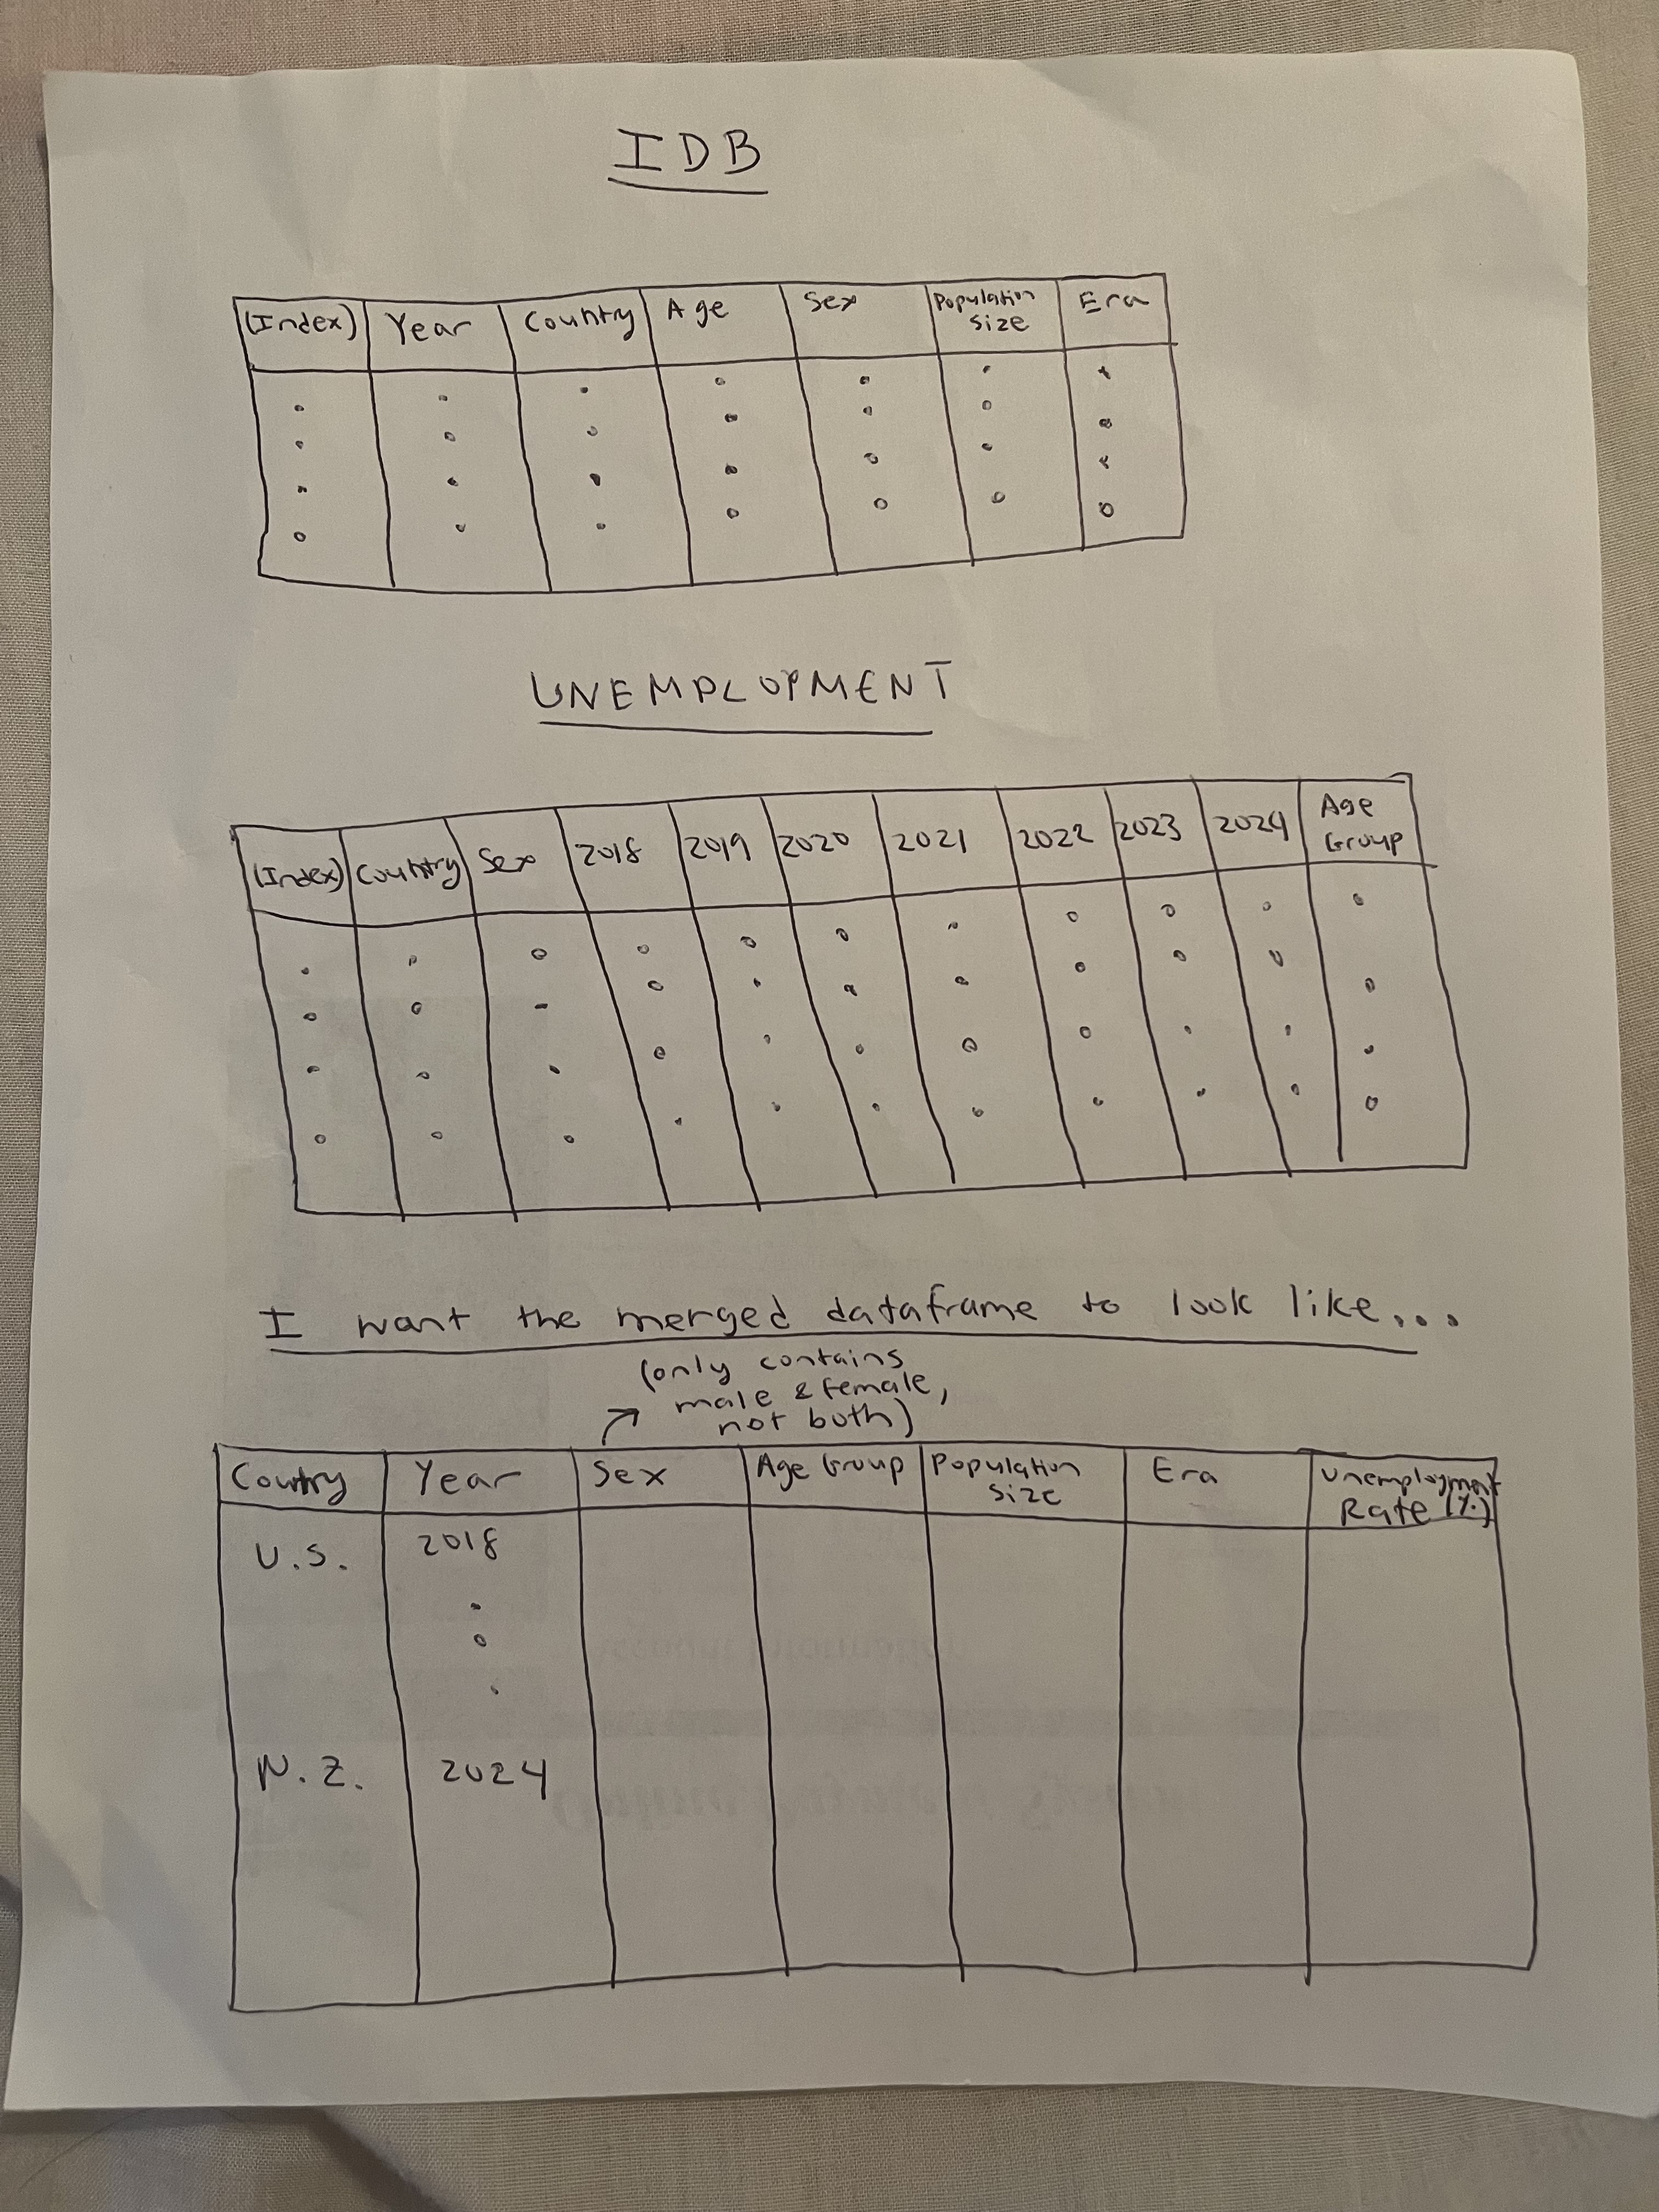

In [16]:
from IPython.display import Image
Image(filename='merged_df_sketch.jpeg')

Below, I conduct the steps in order to create the final merged dataframe as shown in my sketch and to save the merged dataframe to a csv file - "merged_data.csv""

In [17]:
import pandas as pd

# Loading in the transformed datasets:
idb_df = pd.read_csv("idb_transformed.csv")
unemployment_df = pd.read_csv("unemployment_transformed.csv")

# Filtering out the 'Sex' = 0 rows in the IDB dataset:
idb_filtered = idb_df[idb_df['Sex'] != 0].copy()

# Converting Sex values 1 and 2 to 'Male' and 'Female':
idb_filtered['Sex'] = idb_filtered['Sex'].map({1: 'Male', 2: 'Female'})

# Creating age groups in the IDB dataset:
def assign_age_group(age):
    if age < 15:
        return "Children (<15)"
    elif 15 <= age <= 24:
        return "Youth (15-24)"
    else:  # age >= 25
        return "Adults (25+)"

idb_filtered['Age Group'] = idb_filtered['Age'].apply(assign_age_group)

# Reshaping the unemployment data from wide to long format:
unemployment_long = pd.melt(
    unemployment_df, 
    id_vars=['country_name', 'sex', 'age_group', 'age_categories'],
    value_vars=['2018', '2019', '2020', '2021', '2022', '2023', '2024'],
    var_name='Year',
    value_name='Unemployment Rate (%)'
)

# Converting year to integer:
unemployment_long['Year'] = unemployment_long['Year'].astype(int)

# Renaming columns in the unemployment df:
unemployment_long = unemployment_long.rename(columns={
    'country_name': 'Country',
    'sex': 'Sex'
})

# Creating Age Group column in unemployment dataframe:
unemployment_long['Age Group'] = unemployment_long.apply(
    lambda row: f"{row['age_categories']} ({row['age_group']})" if row['age_group'] != 'Under 15' 
    else "Children (<15)", axis=1
)

# Grouping the IDB data by Country, Year, Sex, and Age Group to get total population:
idb_grouped = idb_filtered.groupby(['Country', 'Year', 'Sex', 'Age Group']).agg({
    'Population Size': 'sum',
    'Era': 'first'  
}).reset_index()

# Merging the datasets:
merged_df = pd.merge(
    idb_grouped,
    unemployment_long,
    on=['Country', 'Year', 'Sex', 'Age Group'],
    how='inner'
)

# Selecting only the needed columns:
final_df = merged_df[['Country', 'Year', 'Sex', 'Age Group', 'Population Size', 'Era', 'Unemployment Rate (%)']]

# Saving the final merged dataframe to a csv - "merged_data.csv":
final_df.to_csv("merged_data.csv", index=False)

# Displaying the final merged dataframe:
print("FINAL MERGED DF:")
display(final_df.head(84))









FINAL MERGED DF:


,Country,Year,Sex,Age Group,Population Size,Era,Unemployment Rate (%)
0,New Zealand,2018,Female,Adults (25+),1620401,Pre COVID,3.337
1,New Zealand,2018,Female,Children (<15),461004,Pre COVID,4.503
2,New Zealand,2018,Female,Youth (15-24),305831,Pre COVID,11.015
3,New Zealand,2018,Male,Adults (25+),1578033,Pre COVID,2.735
4,New Zealand,2018,Male,Children (<15),486622,Pre COVID,4.193
...,...,...,...,...,...,...,...
79,United States,2024,Female,Children (<15),28517326,Post COVID,3.724
80,United States,2024,Female,Youth (15-24),21762754,Post COVID,7.671
81,United States,2024,Male,Adults (25+),114194617,Post COVID,3.257
82,United States,2024,Male,Children (<15),29863511,Post COVID,4.080


### <span style="color:yellow">DATA EXPLORATION</span>

In the code cells below, I will do some exploratory data analysis (EDA) on the merged dataframe:

In [18]:
# Summary statistics:

print(final_df.describe())

              Year  Population Size  Unemployment Rate (%)
count    84.000000     8.400000e+01              84.000000
mean   2021.000000     2.807486e+07               5.968762
std       2.012012     4.044528e+07               3.455473
min    2018.000000     3.058310e+05               1.975000
25%    2019.000000     4.838482e+05               3.218500
50%    2021.000000     1.133632e+07               4.136500
75%    2023.000000     2.988479e+07               8.867750
max    2024.000000     1.193884e+08              14.946000


A notable observation from the output above is that the average unemployment rate of the US and NZ is close to 6% between 2018-2024.

C:\Users\Yogin\AppData\Local\Temp\ipykernel_19936\1256848928.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=final_df, x="Country", order=final_df["Country"].value_counts().index, palette="viridis")


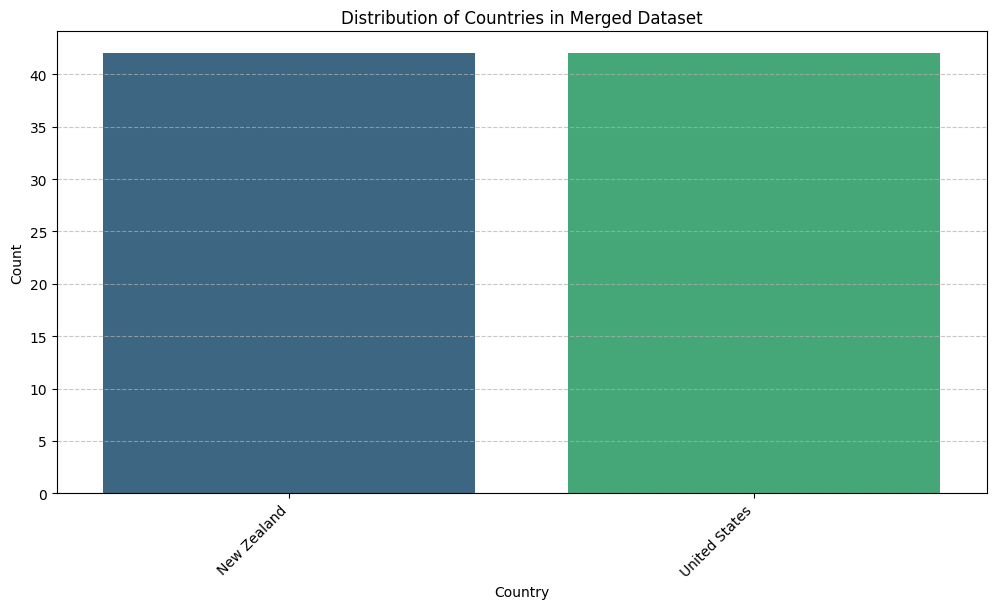

In [19]:
# Country distribution:

plt.figure(figsize=(12, 6))

sns.countplot(data=final_df, x="Country", order=final_df["Country"].value_counts().index, palette="viridis")

plt.xticks(rotation=45, ha="right")

plt.xlabel("Country")
plt.ylabel("Count")
plt.title("Distribution of Countries in Merged Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.7)


plt.show()

From the graph above, it can be seen that there is an even distribution of the countries.

C:\Users\Yogin\AppData\Local\Temp\ipykernel_19936\379732631.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=final_df, x="Era", order=final_df["Era"].value_counts().index, palette="coolwarm")


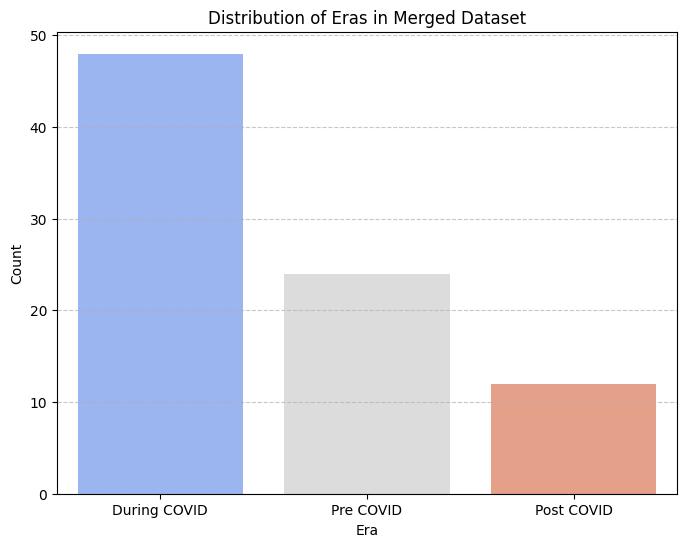

In [20]:
# Era Distribution:

plt.figure(figsize=(8, 6))

sns.countplot(data=final_df, x="Era", order=final_df["Era"].value_counts().index, palette="coolwarm")

plt.xlabel("Era")
plt.ylabel("Count")
plt.title("Distribution of Eras in Merged Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

From the graph above, we can see that our data has the most data points for during Covid, next for pre-Covid, and last for post-Covid. This skew is something that may need to be noted for future analysis.

C:\Users\Yogin\AppData\Local\Temp\ipykernel_19936\174256626.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=final_df, x="Sex", order=final_df["Sex"].value_counts().index, palette="viridis")


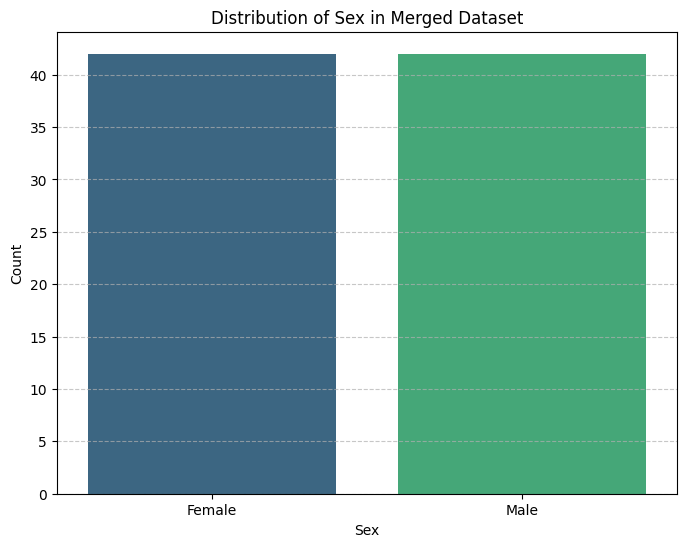

In [21]:
# Sex Distribution:

plt.figure(figsize=(8, 6))

sns.countplot(data=final_df, x="Sex", order=final_df["Sex"].value_counts().index, palette="viridis")


plt.xlabel("Sex")
plt.ylabel("Count")
plt.title("Distribution of Sex in Merged Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()

From the graph above, we can see that there is an even distribution of males and females in this dataset.

C:\Users\Yogin\AppData\Local\Temp\ipykernel_19936\3782854516.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=final_df, x="Age Group", order=final_df["Age Group"].value_counts().index, palette="magma")


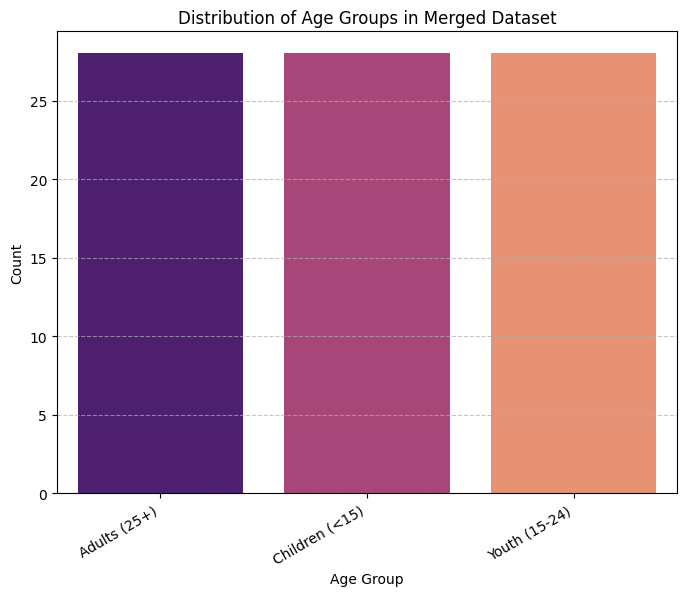

In [22]:
# Age Distribution:

plt.figure(figsize=(8, 6))

sns.countplot(data=final_df, x="Age Group", order=final_df["Age Group"].value_counts().index, palette="magma")

plt.xticks(rotation=30, ha="right")

plt.xlabel("Age Group")
plt.ylabel("Count")
plt.title("Distribution of Age Groups in Merged Dataset")
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.show()


From the graph above, we can see that there is an even distribution of the age groups in this dataset.

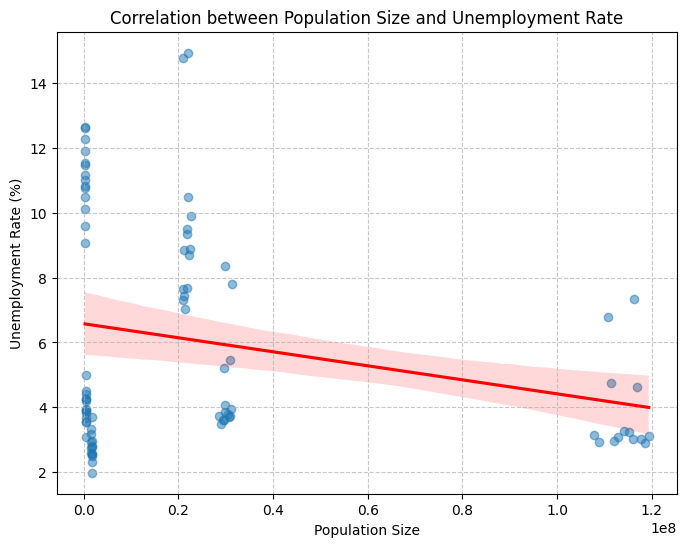

In [23]:
# Correlation between population size and unemployment rate:

plt.figure(figsize=(8, 6))

sns.regplot(
    data=final_df, 
    x="Population Size", 
    y="Unemployment Rate (%)", 
    scatter_kws={"alpha": 0.5},  
    line_kws={"color": "red"}    
)

plt.xlabel("Population Size")
plt.ylabel("Unemployment Rate (%)")
plt.title("Correlation between Population Size and Unemployment Rate")
plt.grid(True, linestyle="--", alpha=0.7)

plt.show()

While quite scattered, overall it seems like as the population size increases, the unemployment rate seems to go down which I find interesting. 

In [24]:
# Checking the unique values in all the columns:

print("Unique Values in Each Column:\n")

for column in final_df.columns:
    unique_values = final_df[column].unique()
    print(f"{column}: {unique_values[:10]}")  # Displaying first 10 unique values for readability
    print(f"Total unique values: {len(unique_values)}\n")


Unique Values in Each Column:

Country: ['New Zealand' 'United States']
Total unique values: 2

Year: [2018 2019 2020 2021 2022 2023 2024]
Total unique values: 7

Sex: ['Female' 'Male']
Total unique values: 2

Age Group: ['Adults (25+)' 'Children (<15)' 'Youth (15-24)']
Total unique values: 3

Population Size: [1620401  461004  305831 1578033  486622  328036 1651947  465676  306594
 1610709]
Total unique values: 84

Era: ['Pre COVID' 'During COVID' 'Post COVID']
Total unique values: 3

Unemployment Rate (%): [ 3.337  4.503 11.015  2.735  4.193 12.65   3.172  4.419 11.493  2.598]
Total unique values: 83



From the output above, it doesn't seem like there are any "odd" values in any of the columns.

In [25]:
# Checking for missing/NaN values:

missing_values = final_df.isnull().sum()

nan_values = final_df.isna().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nNaN Values in Each Column:")
print(nan_values)

missing_values = missing_values[missing_values > 0]
nan_values = nan_values[nan_values > 0]

if missing_values.empty and nan_values.empty:
    print("\nNo missing or NaN values found!")
else:
    print("\nColumns with missing values:")
    print(missing_values)

    print("\nColumns with NaN values:")
    print(nan_values)


Missing Values in Each Column:
Country                  0
Year                     0
Sex                      0
Age Group                0
Population Size          0
Era                      0
Unemployment Rate (%)    0
dtype: int64

NaN Values in Each Column:
Country                  0
Year                     0
Sex                      0
Age Group                0
Population Size          0
Era                      0
Unemployment Rate (%)    0
dtype: int64

No missing or NaN values found!


From the output above, it can be seen that there are no missing/NaN values, ensuring our data is ready for analysis.

### <span style="color:yellow">DATA ANALYSIS</span>

Here, I will be completing the data analysis to investigate the following trends for the US and NZ:

- Population size before, during, and after COVID-19

    Based on prior research, I hypothesize that the US took a bigger hit to its population overall compared to NZ during the pandemic because the US did not have a structured response to the pandemic. 
- Gender distributions before, during, and after COVID-19

    I hypothesize that for both the US and NZ, men will have been impacted more by the pandemic. This is because according to the Brookings Institue, "Men are much more likely to die from COVID-19 than women. This is true globally – where the death rate has been about 50% higher for men" (Reeves et al., 2021).
- Age distributions before, during, and after COVID-19

    I hypothesize that for both the US and NZ, older populations will have been impacted more by the pandemic. This is because according to the JAMA Network, "More than 80% of the global COVID-19–related deaths between 2020 and 2021 occurred among people aged 60 years or older" (Harris, 2023). 
- Unemployment rates before, during, and after COVID-19, and potential correlations with demographic variables

    Based on prior research, I hypothesize that the unemployment rate increased during the pandemic and was higher in the US than in NZ. This is because for the US, "In April 2020, the unemployment rate reached 14.8%" (COngress.gov, 2025) whereas for New Zealand, "4.4 percent of the labor force in New Zealand were unemployed as of the first quarter of 2020" (Statisa, 2020). I also hypothesize that women faced greater unemployment than men during the pandemic (at least in the US) because according to the Pew Research Center, "The COVID-19 recession resulted in a steep but transitory contraction in employment, with greater job losses among women than men (Fry, 2022).


**Investigating population size before, during, and after COVID-19:**

(Given that the "Era" column was skewed, most importantly, that there were more "during covid" years than "post covid" years, I decided to not utilize that column as much in this analysis as that could wrongly influence the results.)

Country   New Zealand  United States
count    7.000000e+00   7.000000e+00
mean     4.982203e+06   3.319161e+08
std      1.377065e+05   3.427663e+06
min      4.779927e+06   3.268382e+08
25%      4.890068e+06   3.299284e+08
50%      4.991442e+06   3.320490e+08
75%      5.081353e+06   3.340932e+08
max      5.161211e+06   3.364822e+08


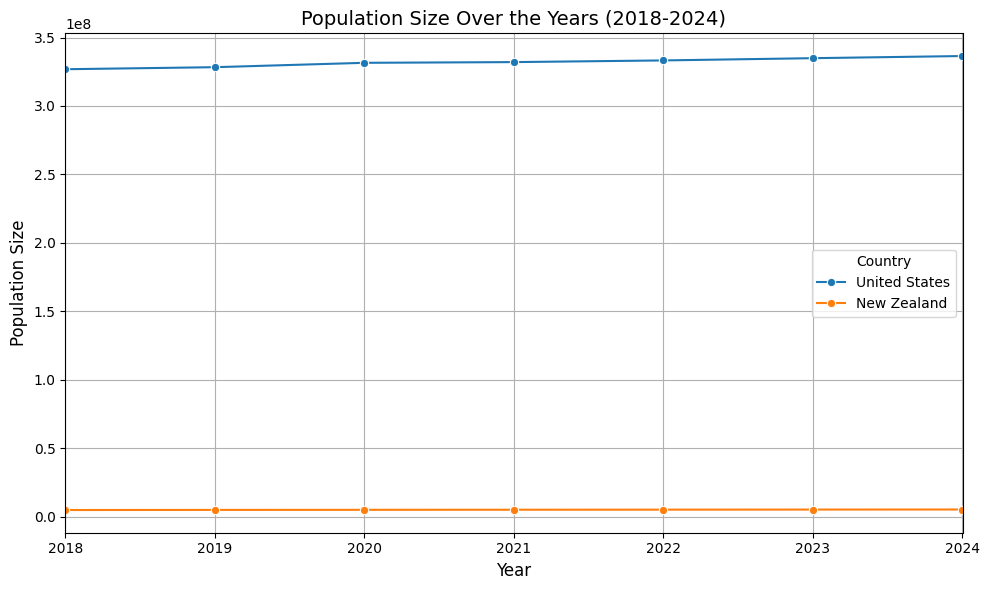

In [26]:
# Descriptive statistics
pop_stats = final_df.groupby(['Year', 'Country'])['Population Size'].sum().unstack()
pop_stats_descriptive = pop_stats.describe()
print(pop_stats_descriptive)

# Graphing
pop_over_years = final_df.groupby(['Year', 'Country'])['Population Size'].sum().unstack()
plt.figure(figsize=(10, 6))
sns.lineplot(data=pop_over_years, x=pop_over_years.index, y='United States', label='United States', marker='o')
sns.lineplot(data=pop_over_years, x=pop_over_years.index, y='New Zealand', label='New Zealand', marker='o')
plt.title('Population Size Over the Years (2018-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Population Size', fontsize=12)
plt.legend(title='Country')
plt.xlim(2018, 2024) 
plt.grid(True)
plt.tight_layout()
plt.show()



From the line plot above, it seems like both populations remained relatively steady from pre to post Covid.

Below, I calculate the percentage change between each "era" for each country to get a better insight on the population changes. (I defined pre Covid as 2019 only, during Covid as 2020 only since this was its peak year, and post Covid as 2024 to avoid any effects of a skew):

In [27]:
filtered_df = final_df[final_df['Year'].isin([2019, 2020, 2024])]

pop_pivot = filtered_df.groupby(["Country", "Year"])["Population Size"].sum().unstack()

def calculate_percentage_change(start, end):
    return ((end - start) / start) * 100

for country in ["United States", "New Zealand"]:
    pre_covid_pop = pop_pivot.loc[country, 2019]
    during_covid_pop = pop_pivot.loc[country, 2020]
    post_covid_pop = pop_pivot.loc[country, 2024]
    

    pre_to_during_change = calculate_percentage_change(pre_covid_pop, during_covid_pop)
    during_to_post_change = calculate_percentage_change(during_covid_pop, post_covid_pop)
    
    
    print(f"Population Change for {country}:")
    print(f"  - From Pre-COVID (2019) to During-COVID (2020): {pre_to_during_change:.2f}%")
    print(f"  - From During-COVID (2020) to Post-COVID (2024): {during_to_post_change:.2f}%\n")


Population Change for United States:
  - From Pre-COVID (2019) to During-COVID (2020): 0.97%
  - From During-COVID (2020) to Post-COVID (2024): 1.49%

Population Change for New Zealand:
  - From Pre-COVID (2019) to During-COVID (2020): 1.45%
  - From During-COVID (2020) to Post-COVID (2024): 4.79%



According to the output above, both countries saw a greater population increase from during Covid to post-Covid than they did pre-Covid to during Covid. However, NZ experienced a greater increase overall from 2019 to 2024 (3.52%) than the US (.52%). Hence, this aligns with my hypothesis and does suggest that New Zealand fared better than the US at least in terms of population size during the pandemic.

**Investigating gender distributions before, during, and after COVID-19:**

Country   New Zealand               United States              
Sex            Female          Male        Female          Male
count    7.000000e+00  7.000000e+00  7.000000e+00  7.000000e+00
mean     2.487519e+06  2.494684e+06  1.677995e+08  1.641165e+08
std      6.839483e+04  6.931190e+04  1.349699e+06  2.105422e+06
min      2.387236e+06  2.392691e+06  1.658777e+08  1.609605e+08
25%      2.441684e+06  2.448385e+06  1.669732e+08  1.629553e+08
50%      2.491971e+06  2.499471e+06  1.676308e+08  1.644182e+08
75%      2.536728e+06  2.544625e+06  1.687368e+08  1.653564e+08
max      2.576604e+06  2.584607e+06  1.696684e+08  1.668137e+08


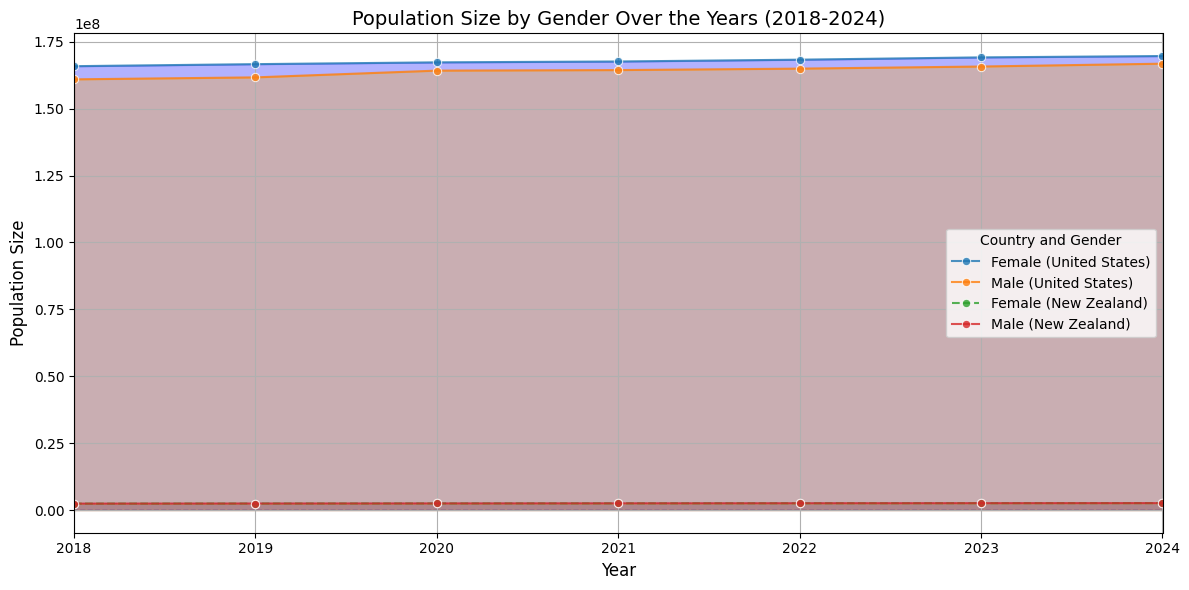

In [28]:
# Descriptive statistics:
pop_stats_gender = final_df.groupby(['Year', 'Country', 'Sex'])['Population Size'].sum().unstack(level=[1,2])
pop_stats_gender_descriptive = pop_stats_gender.describe()
print(pop_stats_gender_descriptive)

# Graphing:
plt.figure(figsize=(12, 6))

sns.lineplot(data=pop_stats_gender['United States'], x=pop_stats_gender.index, y='Female', label='Female (United States)', marker='o', alpha=0.8)
plt.fill_between(pop_stats_gender.index, pop_stats_gender['United States']['Female'], alpha=0.3, color='blue')

sns.lineplot(data=pop_stats_gender['United States'], x=pop_stats_gender.index, y='Male', label='Male (United States)', marker='o', alpha=0.8)
plt.fill_between(pop_stats_gender.index, pop_stats_gender['United States']['Male'], alpha=0.3, color='orange')

sns.lineplot(data=pop_stats_gender['New Zealand'], x=pop_stats_gender.index, y='Female', label='Female (New Zealand)', marker='o', linestyle='--', alpha=0.8)
plt.fill_between(pop_stats_gender.index, pop_stats_gender['New Zealand']['Female'], alpha=0.3, color='blue', linestyle='--')

sns.lineplot(data=pop_stats_gender['New Zealand'], x=pop_stats_gender.index, y='Male', label='Male (New Zealand)', marker='o', alpha=0.8)
plt.fill_between(pop_stats_gender.index, pop_stats_gender['New Zealand']['Male'], alpha=0.3, color='orange')

plt.title('Population Size by Gender Over the Years (2018-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Population Size', fontsize=12)
plt.legend(title='Country and Gender')
plt.xlim(2018, 2024)
plt.grid(True)
plt.tight_layout()
plt.show()




According to the graph above, males and females in New Zealand were nearly identically affected during the pandemic. In the US however, while the overall male population is lower than the overall female population over the years, both populations seem to remain fairly steady. In order to get a closer look into this, I will look at the population percentage difference from 2019 t0 2024 for both males and females in the US:

In [29]:

us_population_2019 = pop_stats_gender.loc[2019, 'United States']
us_population_2024 = pop_stats_gender.loc[2024, 'United States']

female_diff_percentage = ((us_population_2024['Female'] - us_population_2019['Female']) / us_population_2019['Female']) * 100
male_diff_percentage = ((us_population_2024['Male'] - us_population_2019['Male']) / us_population_2019['Male']) * 100


print(f"Percentage change in female population (2019 to 2024) for the United States: {female_diff_percentage:.2f}%")
print(f"Percentage change in male population (2019 to 2024) for the United States: {male_diff_percentage:.2f}%")


Percentage change in female population (2019 to 2024) for the United States: 1.82%
Percentage change in male population (2019 to 2024) for the United States: 3.17%


These results are contrary to my original hypothesis because for New Zealand, there didn't seem to be any significant differences between men and women in their populations from pre to post Covid and for the US, there seems to have been a greater population increase for men than women from pre to post Covid which is not what I was expected because according to prior research, more men died during Covid.

**Investigating Age Distributions Before, During, and After Covid**

Age Group  Adults (25+)  Children (<15)  Youth (15-24)
count      2.000000e+00    2.000000e+00   2.000000e+00
mean       8.109873e+08    2.140891e+08   1.540675e+08
std        1.113535e+09    2.931763e+08   2.115293e+08
min        2.359952e+07    6.782147e+06   4.493752e+06
25%        4.172934e+08    1.104356e+08   7.928064e+07
50%        8.109873e+08    2.140891e+08   1.540675e+08
75%        1.204681e+09    3.177426e+08   2.288544e+08
max        1.598375e+09    4.213960e+08   3.036413e+08


<Figure size 1200x600 with 0 Axes>

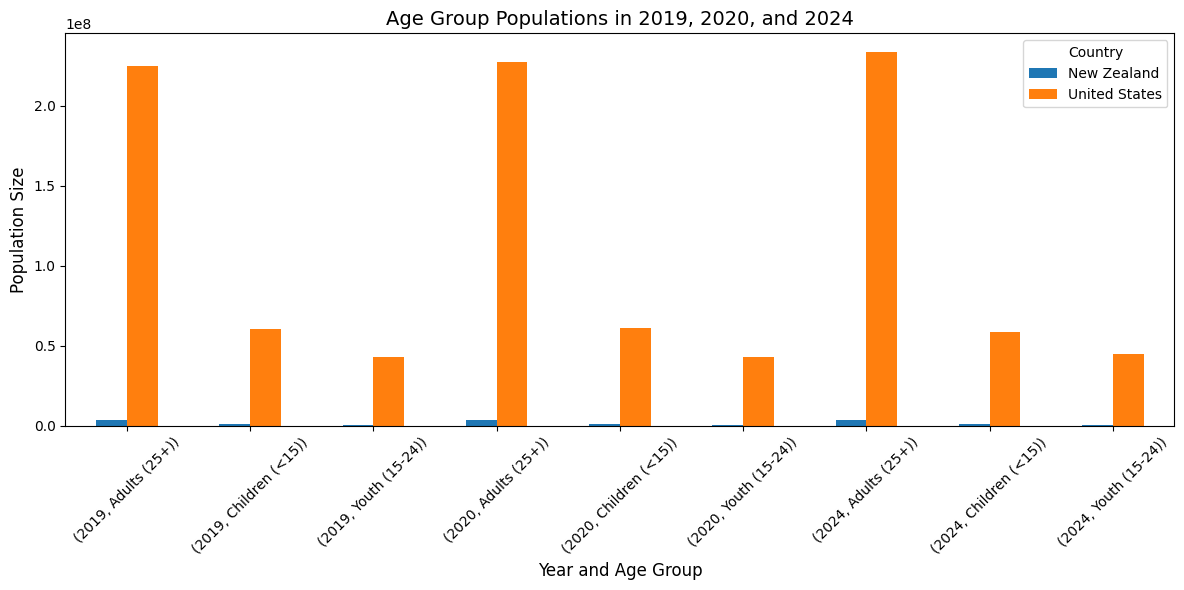

In [30]:
# Descriptive statistics:
age_stats = final_df.groupby(['Country', 'Age Group'])['Population Size'].sum().unstack()
age_stats_descriptive = age_stats.describe()
print(age_stats_descriptive)

# Graphing: 
# (Here I use only 2019 for pre Covid, 2020 for during Covid, and 2024 for post Covid)
age_filtered = final_df[final_df['Year'].isin([2019, 2020, 2024])]
age_pivot = age_filtered.pivot_table(values='Population Size', index=['Year', 'Age Group'], columns='Country', aggfunc='sum')

plt.figure(figsize=(12, 6))
age_pivot.plot(kind='bar', figsize=(12, 6))

plt.title('Age Group Populations in 2019, 2020, and 2024', fontsize=14)
plt.xlabel('Year and Age Group', fontsize=12)
plt.ylabel('Population Size', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Country')
plt.tight_layout()
plt.show()



From the graph above, it can be seen that for both the US and NZ, the population for each age group remained relatively steady before (2019), during (2020), and after (2024) Covid, contrary to my original hypothesis. It does look like, however, that there may have been a slight decrease in the adult population in NZ from 2019 to 2024. To investigate this further, I will be looking at the percent change between these years:

In [31]:
nz_adults = final_df[(final_df['Country'] == 'New Zealand') & (final_df['Age Group'] == 'Adults (25+)')]

pop_2019 = nz_adults[nz_adults['Year'] == 2019]['Population Size'].sum()
pop_2024 = nz_adults[nz_adults['Year'] == 2024]['Population Size'].sum()

percentage_change_nz_adults = ((pop_2024 - pop_2019) / pop_2019) * 100
print(f"Percentage change in the adult population in New Zealand from 2019 to 2024: {percentage_change_nz_adults:.2f}%")

Percentage change in the adult population in New Zealand from 2019 to 2024: 8.08%


There was actually a percent increase between these years again, contradictory to my original hypothesis.

**Unemployment rates before, during, and after COVID-19, and potential correlations with demographic variables**

Country  New Zealand  United States
count       7.000000       7.000000
mean        5.961714       5.975810
std         0.601877       1.870354
min         4.963667       4.858167
25%         5.634500       4.944750
50%         6.111833       5.224333
75%         6.296833       5.927417
max         6.793833      10.003833


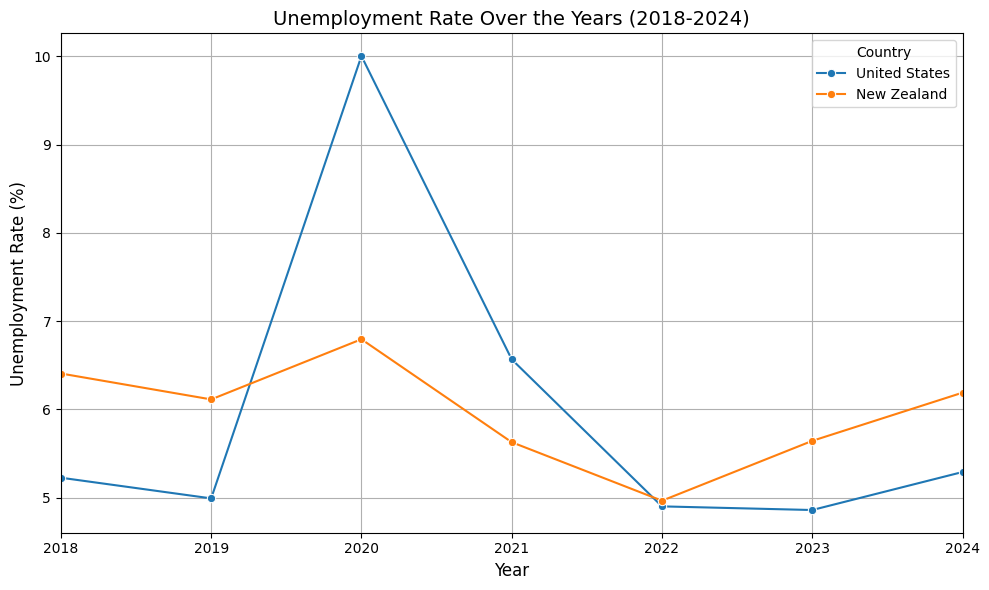

In [32]:
# Descriptive statistics:
unemployment_stats = final_df.groupby(['Year', 'Country'])['Unemployment Rate (%)'].mean().unstack().describe()
print(unemployment_stats)


# Unemployment rates by country over the years:
unemployment_over_years = final_df.groupby(['Year', 'Country'])['Unemployment Rate (%)'].mean().unstack()

plt.figure(figsize=(10, 6))
sns.lineplot(data=unemployment_over_years, x=unemployment_over_years.index, y='United States', label='United States', marker='o')
sns.lineplot(data=unemployment_over_years, x=unemployment_over_years.index, y='New Zealand', label='New Zealand', marker='o')

plt.title('Unemployment Rate Over the Years (2018-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Unemployment Rate (%)', fontsize=12)
plt.legend(title='Country')
plt.xlim(2018, 2024)
plt.grid(True)
plt.tight_layout()
plt.show()



From the graph above, it can be seen that unemployment peaked during 2020 (the peak Covid year) for both the US and NZ. The unemployment rate was also significantly higher in the US compared to NZ, aligning with my original hypothesis.

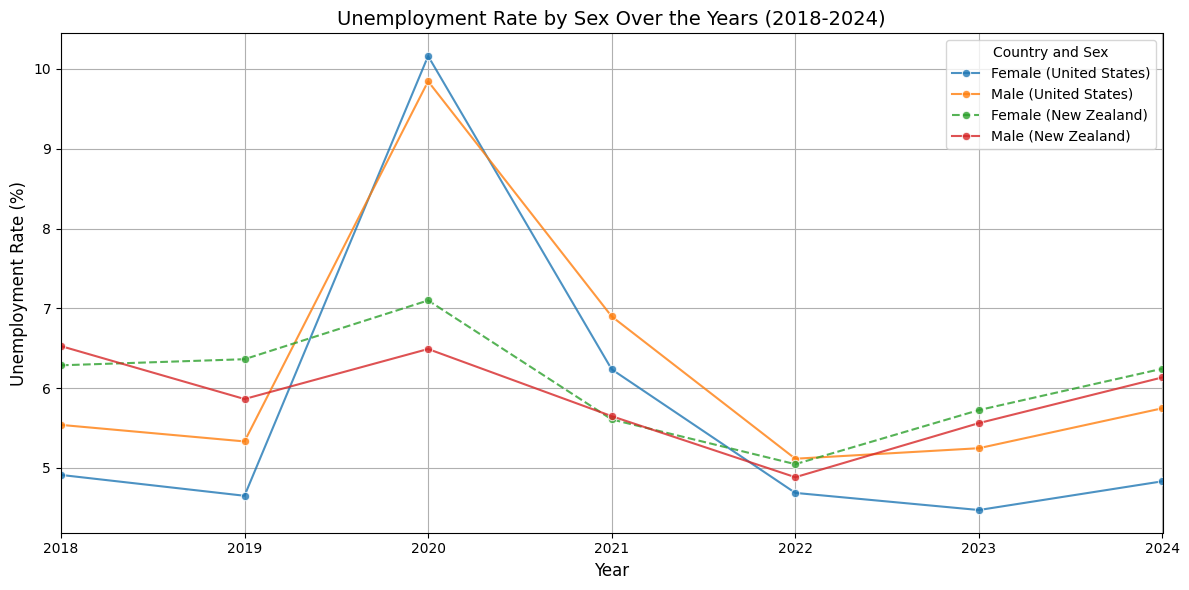

In [33]:
# Unemployment rates by country and and sex over the years:

unemployment_over_years_sex = final_df.groupby(['Year', 'Country', 'Sex'])['Unemployment Rate (%)'].mean().unstack(level='Sex')

plt.figure(figsize=(12, 6))

us_data = unemployment_over_years_sex.xs('United States', level='Country').reset_index()
nz_data = unemployment_over_years_sex.xs('New Zealand', level='Country').reset_index()

sns.lineplot(data=us_data, x='Year', y='Female', label='Female (United States)', marker='o', alpha=0.8)
sns.lineplot(data=us_data, x='Year', y='Male', label='Male (United States)', marker='o', alpha=0.8)

sns.lineplot(data=nz_data, x='Year', y='Female', label='Female (New Zealand)', marker='o', linestyle='--', alpha=0.8)
sns.lineplot(data=nz_data, x='Year', y='Male', label='Male (New Zealand)', marker='o', alpha=0.8)

plt.title('Unemployment Rate by Sex Over the Years (2018-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Unemployment Rate (%)', fontsize=12)
plt.legend(title='Country and Sex')
plt.xlim(2018, 2024)
plt.grid(True)
plt.tight_layout()
plt.show()




From the graph above, it can be seen that for the US, before the pandemic, the unemployment rate was higher for men than for women. However then, as the pandemic began to approach and peak, the unemployment rate for women surpassed the unemployment rate for men, aligning with my original hypothesis. Then, a bit into and after the pandemic, the unemployment rate for women was lower than men again. 

For New Zealand, from 2019 to 2024, the unemployment rate for women continues to be above that for men except in 2021 where they're about the same.

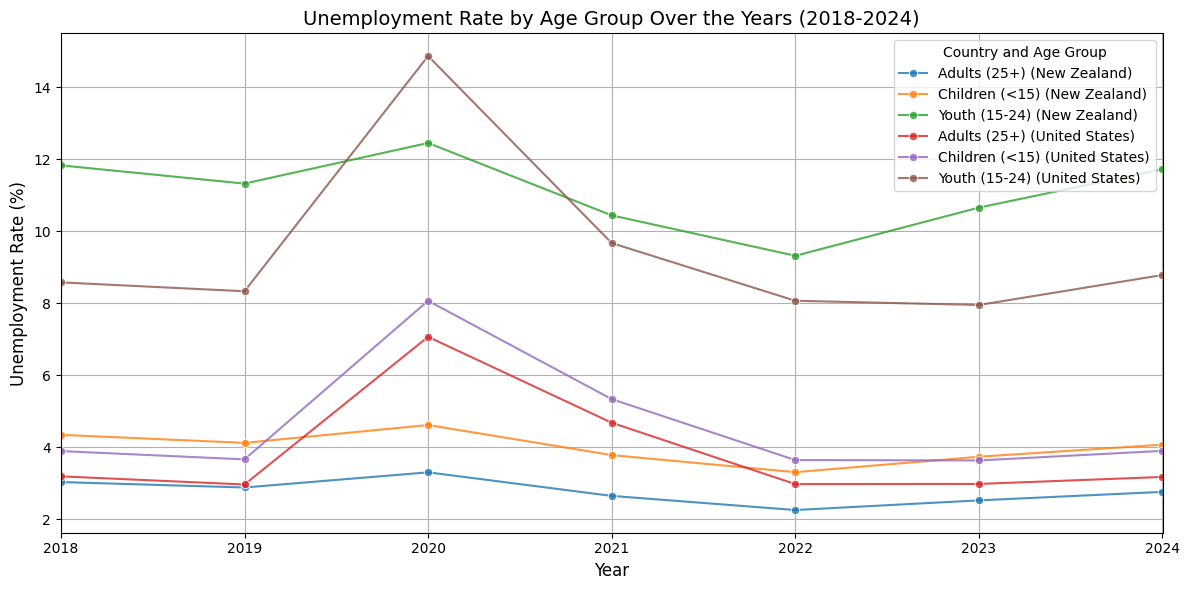

In [34]:
# Unemployment rate by country and age over the years:

unemployment_over_years_age = final_df.groupby(['Year', 'Country', 'Age Group'])['Unemployment Rate (%)'].mean().unstack(level='Age Group')

plt.figure(figsize=(12, 6))

nz_data_age = unemployment_over_years_age.xs('New Zealand', level='Country').reset_index()
us_data_age = unemployment_over_years_age.xs('United States', level='Country').reset_index()

sns.lineplot(data=nz_data_age, x='Year', y='Adults (25+)', label='Adults (25+) (New Zealand)', marker='o', alpha=0.8)
sns.lineplot(data=nz_data_age, x='Year', y='Children (<15)', label='Children (<15) (New Zealand)', marker='o', alpha=0.8)
sns.lineplot(data=nz_data_age, x='Year', y='Youth (15-24)', label='Youth (15-24) (New Zealand)', marker='o', alpha=0.8)

sns.lineplot(data=us_data_age, x='Year', y='Adults (25+)', label='Adults (25+) (United States)', marker='o', alpha=0.8)
sns.lineplot(data=us_data_age, x='Year', y='Children (<15)', label='Children (<15) (United States)', marker='o', alpha=0.8)
sns.lineplot(data=us_data_age, x='Year', y='Youth (15-24)', label='Youth (15-24) (United States)', marker='o', alpha=0.8)

plt.title('Unemployment Rate by Age Group Over the Years (2018-2024)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Unemployment Rate (%)', fontsize=12)
plt.legend(title='Country and Age Group')
plt.xlim(2018, 2024)
plt.grid(True)
plt.tight_layout()
plt.show()


From this graph, it's interesting to see that across all age groups and countries, the unemployment for all of them peaked during 2020. For the US specifically, after 2020, the unemployment rate for all age groups overall declined from the pandemic peak in 2020. For New Zealand, they seemed to go back up a little after 2022. 

### <span style="color:yellow">DATA LOADING</span>

Here, I will be connecting the data from my merged dataframe csv file - "merged_data.csv" to SQL where I will be created a schema for it and an ERD diagram:

In [96]:
import pandas as pd
from sqlalchemy import create_engine, text

user = 'root'
password = 'mysqlpassword'
host = 'localhost'
port = '3306'  
database = 'midterm_db'

engine = create_engine(f'mariadb+mariadbconnector://{user}:{password}@{host}:{port}/{database}')

df = pd.read_csv("merged_data.csv")

def insert_unique_values(table, column_name, df_column):
    unique_values = df[df_column].unique()
    
    for value in unique_values:
        column_name_in_db = column_name + "Name"
        query = f"INSERT IGNORE INTO {table} ({column_name_in_db}) VALUES ('{value}')"
        
        with engine.connect() as conn:
            conn.execute(text(query))
            conn.commit()  

insert_unique_values("Country", "Country", "Country")
insert_unique_values("Era", "Era", "Era")
insert_unique_values("AgeGroup", "AgeGroup", "Age Group")
insert_unique_values("Sex", "Sex", "Sex")

def get_foreign_key(table, column, value):
    column_name_in_db = column + "Name"
    query = f"SELECT {table}ID FROM {table} WHERE {column_name_in_db} = '{value}'"
    
    with engine.connect() as conn:
        result = conn.execute(text(query)).fetchone()
        if result:
            return result[0]
        else:
            return None

tables = ["Country", "Era", "AgeGroup", "Sex"]
for table in tables:
    query = f"SELECT * FROM {table}"
    with engine.connect() as conn:
        result = conn.execute(text(query)).fetchall()

df["CountryID"] = df["Country"].apply(lambda x: get_foreign_key("Country", "Country", x))
df["EraID"] = df["Era"].apply(lambda x: get_foreign_key("Era", "Era", x))
df["AgeGroupID"] = df["Age Group"].apply(lambda x: get_foreign_key("AgeGroup", "AgeGroup", x))
df["SexID"] = df["Sex"].apply(lambda x: get_foreign_key("Sex", "Sex", x))

df = df.rename(columns={"Unemployment Rate (%)": "Unemployment_Rate", "Population Size": "Population_Size"})

population_data = df[["CountryID", "Year", "SexID", "AgeGroupID", "EraID", "Population_Size", "Unemployment_Rate"]]

valid_data = population_data.dropna()

for _, row in valid_data.iterrows():
    query = f"""
    INSERT INTO PopulationData (CountryID, Year, SexID, AgeGroupID, EraID, Population_Size, Unemployment_Rate)
    VALUES ({int(row['CountryID'])}, {int(row['Year'])}, {int(row['SexID'])}, {int(row['AgeGroupID'])}, {int(row['EraID'])}, 
            {int(row['Population_Size'])}, {float(row['Unemployment_Rate'])})
    """
    
    with engine.connect() as conn:
        conn.execute(text(query))
        conn.commit() 

My SQL script where I create my schema is in the file called "midterm_sql_script_1.sql".

For reference, here is my script below:

In [97]:
"""

drop database if exists midterm_db;

CREATE DATABASE midterm_db;

USE midterm_db;


-- Table for Countries
CREATE TABLE Country (
    CountryID INT PRIMARY KEY AUTO_INCREMENT,
    CountryName VARCHAR(50) UNIQUE
);

-- Table for Eras
CREATE TABLE Era (
    EraID INT PRIMARY KEY AUTO_INCREMENT,
    EraName VARCHAR(20) UNIQUE
);

-- Table for Age Groups
CREATE TABLE AgeGroup (
    AgeGroupID INT PRIMARY KEY AUTO_INCREMENT,
    AgeGroupName VARCHAR(20) UNIQUE
);

-- Table for Sex
CREATE TABLE Sex (
    SexID INT PRIMARY KEY AUTO_INCREMENT,
    SexName VARCHAR(10) UNIQUE
);

-- Main Table for Population and Unemployment Data
CREATE TABLE PopulationData (
    PopulationID INT PRIMARY KEY AUTO_INCREMENT,
    CountryID INT,
    Year INT,
    SexID INT,
    AgeGroupID INT,
    EraID INT,
    Population_Size INT,
    Unemployment_Rate DECIMAL(5,3),
    FOREIGN KEY (CountryID) REFERENCES Country(CountryID),
    FOREIGN KEY (SexID) REFERENCES Sex(SexID),
    FOREIGN KEY (AgeGroupID) REFERENCES AgeGroup(AgeGroupID),
    FOREIGN KEY (EraID) REFERENCES Era(EraID),
    UNIQUE (CountryID, Year, SexID, AgeGroupID)
);


"""

'\n\ndrop database if exists midterm_db;\n\nCREATE DATABASE midterm_db;\n\nUSE midterm_db;\n\n\n-- Table for Countries\nCREATE TABLE Country (\n    CountryID INT PRIMARY KEY AUTO_INCREMENT,\n    CountryName VARCHAR(50) UNIQUE\n);\n\n-- Table for Eras\nCREATE TABLE Era (\n    EraID INT PRIMARY KEY AUTO_INCREMENT,\n    EraName VARCHAR(20) UNIQUE\n);\n\n-- Table for Age Groups\nCREATE TABLE AgeGroup (\n    AgeGroupID INT PRIMARY KEY AUTO_INCREMENT,\n    AgeGroupName VARCHAR(20) UNIQUE\n);\n\n-- Table for Sex\nCREATE TABLE Sex (\n    SexID INT PRIMARY KEY AUTO_INCREMENT,\n    SexName VARCHAR(10) UNIQUE\n);\n\n-- Main Table for Population and Unemployment Data\nCREATE TABLE PopulationData (\n    PopulationID INT PRIMARY KEY AUTO_INCREMENT,\n    CountryID INT,\n    Year INT,\n    SexID INT,\n    AgeGroupID INT,\n    EraID INT,\n    Population_Size INT,\n    Unemployment_Rate DECIMAL(5,3),\n    FOREIGN KEY (CountryID) REFERENCES Country(CountryID),\n    FOREIGN KEY (SexID) REFERENCES Sex(SexI

Below is a screenshot of my ER diagram (also in the file "ER_diagram.pdf"):

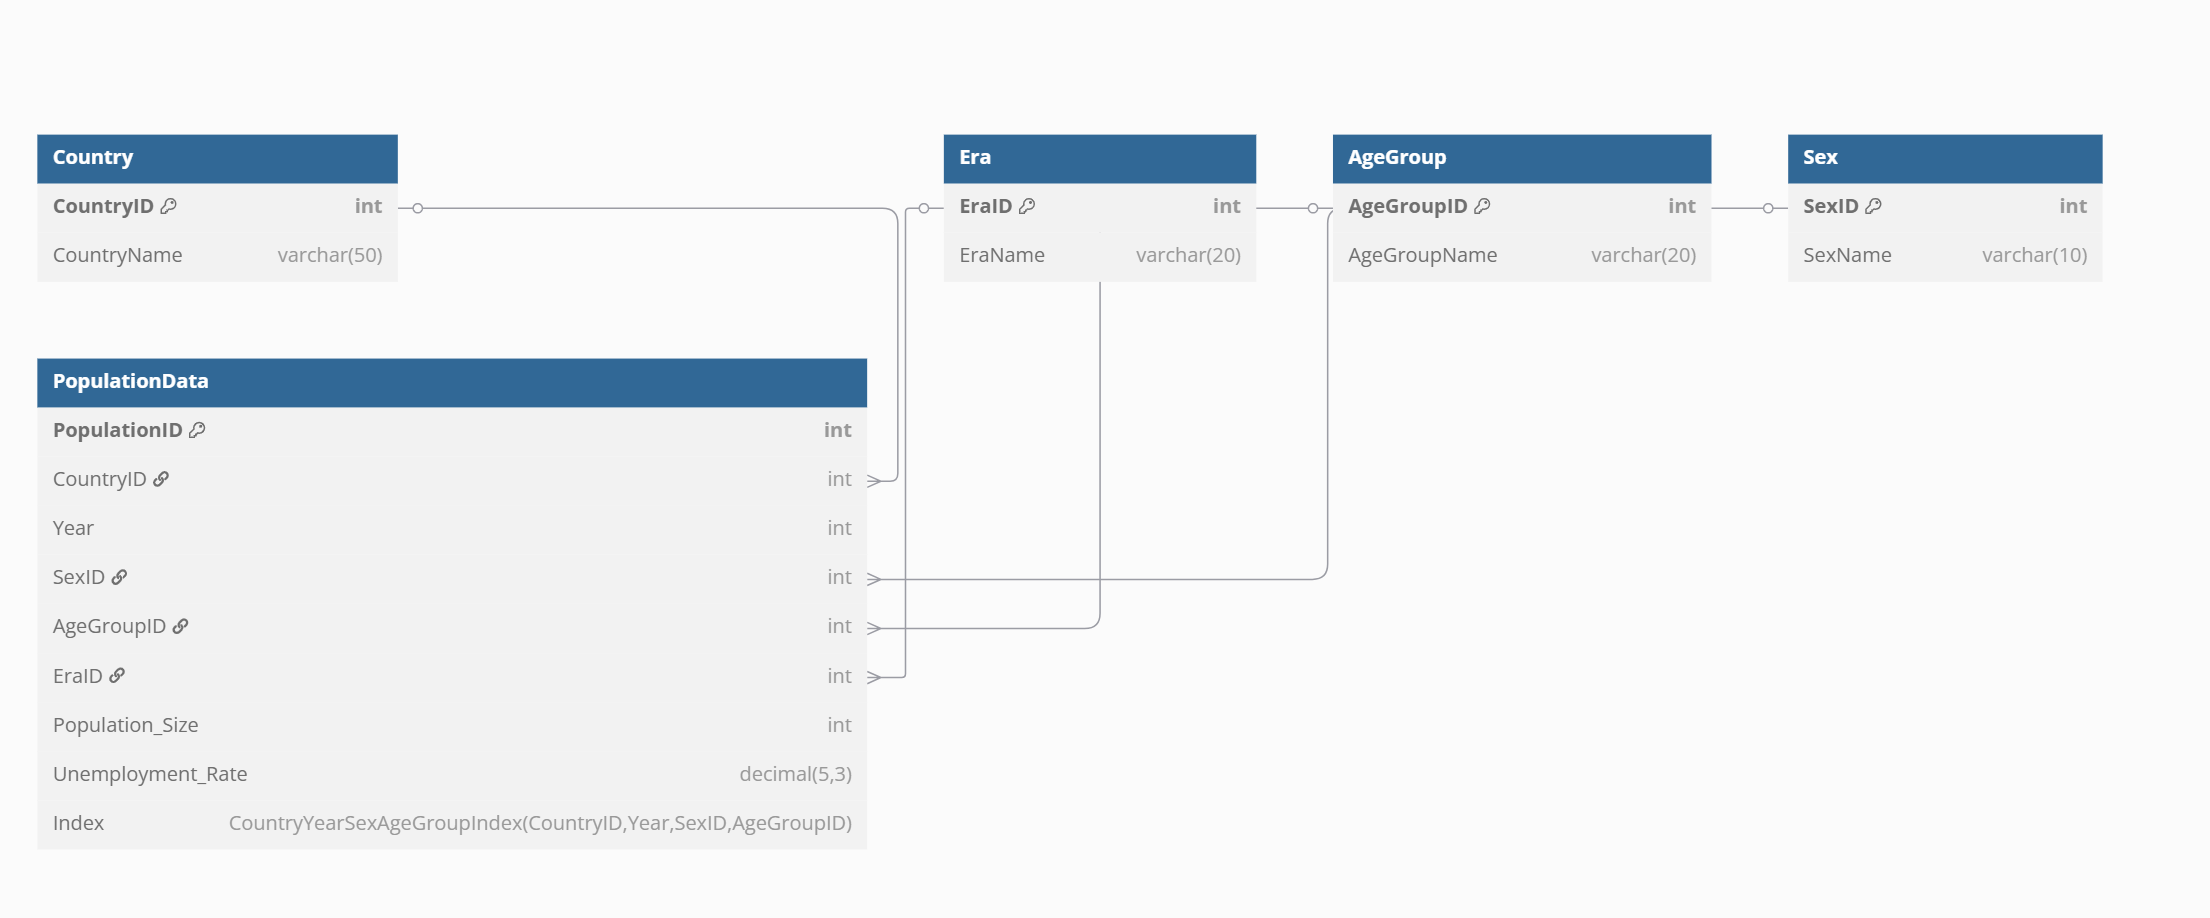

In [99]:
from IPython.display import Image
Image(filename='ERD_screenshot.png')

### <span style="color:yellow">CONCLUSION AND FUTURE DIRECTIONS</span>

From the visualizations and analysis above, the main conclusions of this project are:

- Both the US ans NZ faced peek unemployment during 2020.
- Women, although typically at lower unemployment rates than men in the US, faced higher unemployment rates during 2020.
- All age groups, regardless of country, faced the highest unemployment rates in 2020.

In the future, I think that further socio-poltical environments should be looked at for this study since there were probably many other global events between 2019-2024 that could have caused fluctuations to populations and economies outside of the pandemic.

### <span style="color:yellow">CITATIONS</span>

- At least 65,000 more men than women have died from COVID-19 in the US. (n.d.). Brookings. https://www.brookings.edu/articles/at-least-65000-more-men-than-women-have-died-from-covid-19-in-the-us/ (accessed 3/16/25)
- Fry, R. (2022, January 14). Some gender disparities widened in the U.S. workforce during the pandemic. Pew Research Center. https://www.pewresearch.org/short-reads/2022/01/14/some-gender-disparities-widened-in-the-u-s-workforce-during-the-pandemic/ (accessed 3/16/25)
- Harris, E. (2023). Most COVID-19 Deaths Worldwide Were Among Older People. JAMA. https://doi.org/10.1001/jama.2023.1554 (accessed 3/16/25)
- Islam, S. (2024). Global Unemployment Data. Kaggle.com. https://www.kaggle.com/datasets/sazidthe1/global-unemployment-data?select=global_unemployment_data.csv (accessed 3/13/25)
- Parker, R. (n.d.). https://administrativelawreview.org/wp-content/uploads/sites/2/2021/03/10.-ALR-73.1_Parker-NZ_US_FINAL.pdf (accessed 3/12/25)
- New Zealand - unemployment rate 2020 | Statista. (2020). Statista. https://www.statista.com/statistics/727448/new-zealand-unemployment-rate/ (accessed 3/16/25)
- Unemployment Rates During the COVID-19 Pandemic. (2025). Congress.gov. https://www.congress.gov/crs-product/R46554 (accessed 3/16/25)
- US Census Bureau. (2024). Census.gov. Census.gov. https://www.census.gov/ (accessed 3/12/25)
- U.S. Department of Health and Human Services. (2024). COVID-19 Vaccines. HHS.gov. https://www.hhs.gov/coronavirus/covid-19-vaccines/index.html (accessed 3/12/25)
- Walton, M., Pletzer, V., Teunissen, T., Lumley, T., & Hanlon, T. (2023). Adverse Events Following the BNT162b2 mRNA COVID-19 Vaccine (Pfizer-BioNTech) in Aotearoa New Zealand. NIH Drug Safety, 46(9), 867–879. https://doi.org/10.1007/s40264-023-01332-1 (accessed 3/12/25)


‌

‌

‌